# E-Commerce Revenue & Customer Analytics

## Business Question

What is driving revenue and profit, which customers and products are most valuable, and where is the business losing money?

## Tech Stack
- PostgresSQL
- SQL
- Python
- Pandas
- NumPy
- Matplotlib
- Power BI

## Analysis Areas
1. Revenue Analysis
2. Customer Analysis
3. Product Analysis
4. Operational Analysis
5. Customer Segmentation
6. Business Recommendations

In [107]:
#imported libraries
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
print("Libraries imported successfully")

Libraries imported successfully


In [108]:

import os

print(os.getcwd())

c:\Users\surya\OneDrive\Desktop\E-Commerce-Revenue-Customer-Analytics\python


In [109]:
import os

print(os.listdir()) #shows exactly what folder the notebook is currently using.

['ecommerce_eda.ipynb']


In [110]:
import pandas as pd

customers = pd.read_csv("../data/raw/Olist dataset/olist_customers_dataset.csv")

geolocation = pd.read_csv("../data/raw/Olist dataset/olist_geolocation_dataset.csv")

order_items = pd.read_csv("../data/raw/Olist dataset/olist_order_items_dataset.csv")

payments = pd.read_csv("../data/raw/Olist dataset/olist_order_payments_dataset.csv")

reviews = pd.read_csv("../data/raw/Olist dataset/olist_order_reviews_dataset.csv")

orders = pd.read_csv("../data/raw/Olist dataset/olist_orders_dataset.csv")

products = pd.read_csv("../data/raw/Olist dataset/olist_products_dataset.csv")

sellers = pd.read_csv("../data/raw/Olist dataset/olist_sellers_dataset.csv")

category_translation = pd.read_csv("../data/raw/Olist dataset/product_category_name_translation.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [111]:
#check dataset sizes
print("Customers:", customers.shape)
print("Geolocation:", geolocation.shape)
print("Order Items:", order_items.shape)
print("Payments:", payments.shape)
print("Reviews:", reviews.shape)
print("Orders:", orders.shape)
print("Products:", products.shape)
print("Sellers:", sellers.shape)
print("Category Translation:", category_translation.shape)

Customers: (99441, 5)
Geolocation: (1000163, 5)
Order Items: (112650, 7)
Payments: (103886, 5)
Reviews: (99224, 7)
Orders: (99441, 8)
Products: (32951, 9)
Sellers: (3095, 4)
Category Translation: (71, 2)


In [112]:

#inspecting the columns
datasets = {
    "customers": customers,
    "geolocation": geolocation,
    "order_items": order_items,
    "payments" : payments,
    "reviews" : reviews,
    "orders" : orders,
    "products" : products,
    "sellers" : sellers,
    "category_translation": category_translation
}

for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print(df.columns.tolist())



CUSTOMERS
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

GEOLOCATION
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

ORDER_ITEMS
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

PAYMENTS
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

REVIEWS
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

ORDERS
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

PRODUCTS
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'prod

In [113]:
#check data types
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print(df.dtypes)


CUSTOMERS
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

GEOLOCATION
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object

ORDER_ITEMS
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

PAYMENTS
order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64
dtype: object

REVIEWS
review_id                    str
order_id                     str
review_score               int64
review_comment_title         str
review_comment

In [114]:
#check missing values
for name, df in datasets.items():
    print(f"\n{name.upper()} - Missing Values")
    print(df.isnull().sum().sort_values(ascending=False))


CUSTOMERS - Missing Values
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

GEOLOCATION - Missing Values
geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

ORDER_ITEMS - Missing Values
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

PAYMENTS - Missing Values
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

REVIEWS - Missing Values
review_comment_title       87656
review_comment_message     58247
review_id                      0
review_score                   0
order_id                       0
review_creation_date  

In [115]:
#check duplicate rows
for name, df in datasets.items():
    print(
        f"{name}: {df.duplicated().sum()} duplicate rows"
    )

customers: 0 duplicate rows
geolocation: 261831 duplicate rows
order_items: 0 duplicate rows
payments: 0 duplicate rows
reviews: 0 duplicate rows
orders: 0 duplicate rows
products: 0 duplicate rows
sellers: 0 duplicate rows
category_translation: 0 duplicate rows


In [116]:
#Basic statistical summary

print("ORDER ITEMS")
display(order_items.describe())

print("\nPAYMENTS")
display(payments.describe())

print("\nREVIEWS")
display(reviews.describe())

print("\nPRODUCTS")
display(products.describe())

ORDER ITEMS


,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000



PAYMENTS


,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000



REVIEWS


,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000



PRODUCTS


,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [117]:
#convert order purchase timestamp to datetime
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

#Merge orders with order items 
order_sales = order_items.merge(
    orders[["order_id", "order_purchase_timestamp", "order_status"]],
    on="order_id",
    how="left"
)

#calculate revenue
order_sales["revenue"] = order_sales["price"]

#create month column
order_sales["month"] = order_sales["order_purchase_timestamp"].dt.to_period("M")

#Display result
order_sales.head()


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,order_status,revenue,month
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02,delivered,58.90,2017-09
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06,delivered,239.90,2017-04
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31,delivered,199.00,2018-01
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35,delivered,12.99,2018-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51,delivered,199.90,2017-02


In [118]:
#Monthly revenue
monthly_revenue = (
    order_sales
    .groupby("month")["revenue"]
    .sum()
    .reset_index()
)

#convert month back to datetime for plotting
monthly_revenue["month"] = monthly_revenue["month"].dt.to_timestamp()

#Display monthly revenue
monthly_revenue

,month,revenue
0,2016-09-01,267.36
1,2016-10-01,49507.66
2,2016-12-01,10.90
3,2017-01-01,120312.87
4,2017-02-01,247303.02
5,2017-03-01,374344.30
6,2017-04-01,359927.23
7,2017-05-01,506071.14
8,2017-06-01,433038.60
9,2017-07-01,498031.48


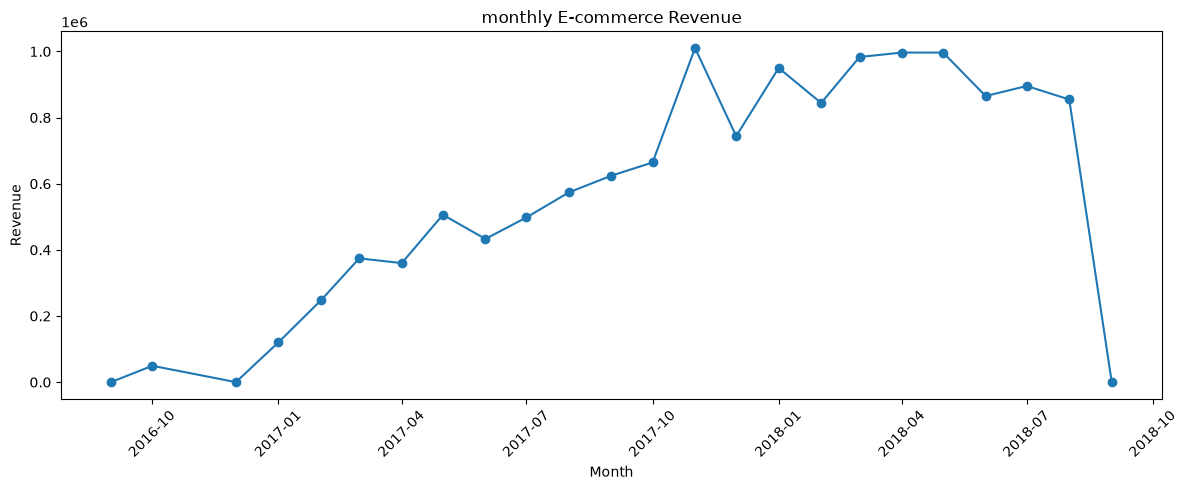

In [119]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_revenue["month"],
    monthly_revenue["revenue"],
    marker="o"
)

plt.title("monthly E-commerce Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [120]:
#calculate month-over-month (MOM) revenue growth

monthly_revenue["MoM_Growth_%"] = (
    monthly_revenue["revenue"].pct_change() * 100
)

#Round the result
monthly_revenue["MoM_Growth_%"] = monthly_revenue["MoM_Growth_%"].round(2)

#Display the result
monthly_revenue

,month,revenue,MoM_Growth_%
0,2016-09-01,267.36,NaN
1,2016-10-01,49507.66,18417.23
2,2016-12-01,10.90,-99.98
3,2017-01-01,120312.87,1103687.80
4,2017-02-01,247303.02,105.55
5,2017-03-01,374344.30,51.37
6,2017-04-01,359927.23,-3.85
7,2017-05-01,506071.14,40.60
8,2017-06-01,433038.60,-14.43
9,2017-07-01,498031.48,15.01


In [121]:
#check the date range of the dataset

print("Earliest order date:")
print(orders["order_purchase_timestamp"].min())

print("\nLatest order date:")
print(orders["order_purchase_timestamp"].max())


Earliest order date:
2016-09-04 21:15:19

Latest order date:
2018-10-17 17:30:18


In [122]:
#Monthly revenue and order count

monthly_summary = (
    order_sales
    .groupby("month")
    .agg(
        revenue=("revenue","sum"),
        orders=("order_id","nunique")
    )
    .reset_index()
)

monthly_summary["month"] = monthly_summary["month"].dt.to_timestamp()
monthly_summary

,month,revenue,orders
0,2016-09-01,267.36,3
1,2016-10-01,49507.66,308
2,2016-12-01,10.90,1
3,2017-01-01,120312.87,789
4,2017-02-01,247303.02,1733
5,2017-03-01,374344.30,2641
6,2017-04-01,359927.23,2391
7,2017-05-01,506071.14,3660
8,2017-06-01,433038.60,3217
9,2017-07-01,498031.48,3969


In [123]:
#calculate year over year (YoY) revenue growth
monthly_revenue["YoY_Growth_%"] = (
    monthly_revenue["revenue"].pct_change(periods=12) * 100
)

monthly_revenue["YoY_Growth_%"] = (
    monthly_revenue["YoY_Growth_%"].round(2)
)

monthly_revenue

,month,revenue,MoM_Growth_%,YoY_Growth_%
0,2016-09-01,267.36,NaN,NaN
1,2016-10-01,49507.66,18417.23,NaN
2,2016-12-01,10.90,-99.98,NaN
3,2017-01-01,120312.87,1103687.80,NaN
4,2017-02-01,247303.02,105.55,NaN
5,2017-03-01,374344.30,51.37,NaN
6,2017-04-01,359927.23,-3.85,NaN
7,2017-05-01,506071.14,40.60,NaN
8,2017-06-01,433038.60,-14.43,NaN
9,2017-07-01,498031.48,15.01,NaN


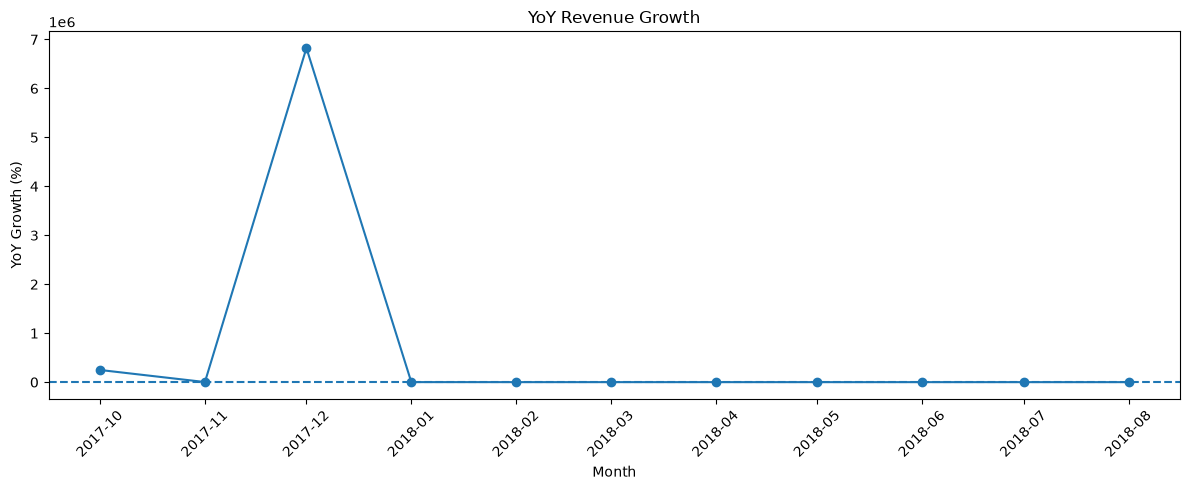

In [124]:
# YoY revenue growth chart

yoy_date = monthly_revenue[
    (monthly_revenue["month"] >= "2017-01-01") &
    (monthly_revenue["month"] <= "2018-08-01")
].copy()

plt.figure(figsize=(12,5))
plt.plot(
    yoy_date["month"],
    yoy_date["YoY_Growth_%"],
    marker='o'
)
plt.axhline(0, linestyle="--")

plt.title("YoY Revenue Growth")
plt.xlabel("Month")
plt.ylabel("YoY Growth (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [125]:
#calculate Average order value (AOV)

total_revenue = order_sales["revenue"].sum()
total_orders = order_sales["order_id"].nunique()

aov = total_revenue / total_orders
print("Total Revenue:",round(total_revenue, 2))
print("Total orders:", total_orders)
print("Average Order Value (AOV):",round(aov, 2))

Total Revenue: 13591643.7
Total orders: 98666
Average Order Value (AOV): 137.75


In [126]:
#calculate AOV using delivered orders only

delivered_sales = order_sales[
    order_sales["order_status"] == "delivered"
]

total_revenue = delivered_sales["revenue"].sum()
total_orders = delivered_sales["order_id"].nunique()

aov = total_revenue / total_orders

print("Delivered Revenue:", round(total_revenue, 2))
print("Delivered orders:", total_orders)
print("AOV:", round(aov, 2))

Delivered Revenue: 13221498.11
Delivered orders: 96478
AOV: 137.04


In [127]:
#Merge order sales with product information

category_sales = order_sales.merge(
    products[["product_id","product_category_name"]],
    on="product_id",
    how="left"
)

#keep delivered orders only
category_sales = category_sales[
    category_sales["order_status"] == "delivered"
]

#calculate revenue by category
category_revenue = (
    category_sales
    .groupby("product_category_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

category_revenue.columns = ["category", "revenue"]
category_revenue.head(10)


,category,revenue
0,beleza_saude,1233131.72
1,relogios_presentes,1166176.98
2,cama_mesa_banho,1023434.76
3,esporte_lazer,954852.55
4,informatica_acessorios,888724.61
5,moveis_decoracao,711927.69
6,utilidades_domesticas,615628.69
7,cool_stuff,610204.10
8,automotivo,578966.65
9,brinquedos,471286.48


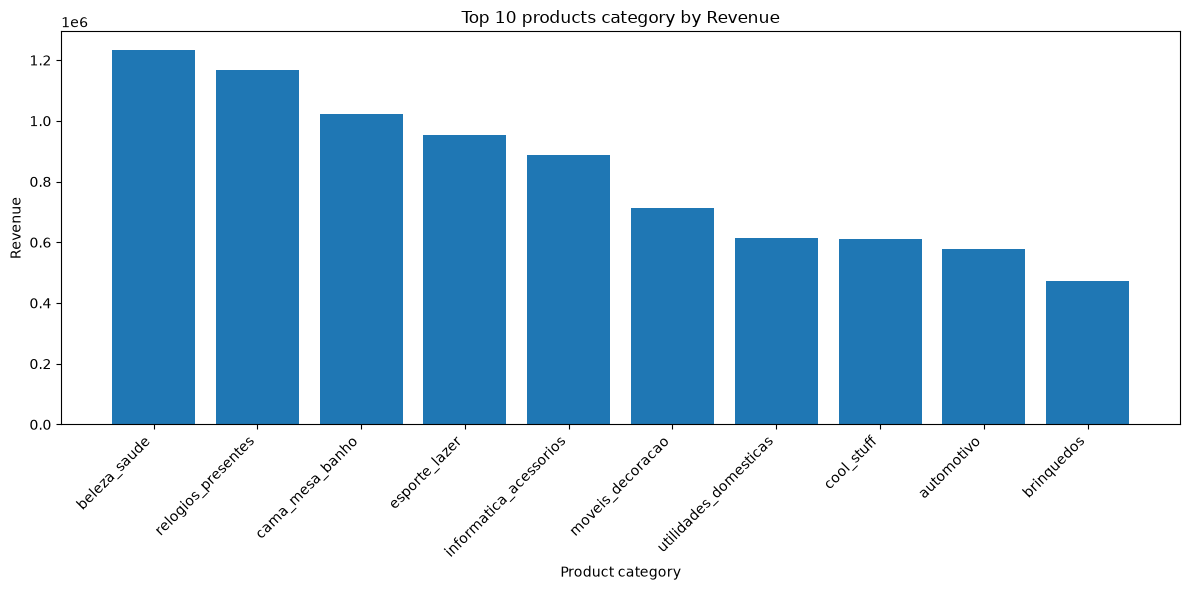

In [128]:
#top 10 revenue generating categories

top_categories = category_revenue.head(10)
plt.figure(figsize=(12, 6))
plt.bar(
    top_categories["category"],
    top_categories["revenue"]
)

plt.title("Top 10 products category by Revenue")
plt.xlabel("Product category")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [129]:
# Merge orders with customer information

customer_orders = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# Count orders for each unique customer
customer_order_counts = (
    customer_orders
    .groupby("customer_unique_id")["order_id"]
    .nunique()
    .reset_index()
)

customer_order_counts.columns = [
    "customer_unique_id",
    "order_count"
]

# Classify customers
customer_order_counts["customer_type"] = customer_order_counts[
    "order_count"
].apply(
    lambda x: "Returning Customer" if x > 1 else "New Customer"
)

# Count each customer type
customer_summary = (
    customer_order_counts
    .groupby("customer_type")
    .size()
    .reset_index(name="customers")
)

customer_summary

,customer_type,customers
0,New Customer,93099
1,Returning Customer,2997


In [130]:
#calculate repeat purchase rate
total_customers = len(customer_order_counts)
returning_customers = (
    customer_order_counts["order_count"] > 1
).sum()

repeat_purchase_rate = (
    returning_customers / total_customers
) * 100
print("Total unique customers:", total_customers)
print("Returning Customers:", returning_customers)
print("Repeat Purchase rate:", round(repeat_purchase_rate, 2), "%")

Total unique customers: 96096
Returning Customers: 2997
Repeat Purchase rate: 3.12 %


In [131]:
#keep delivered orders only
rfm_data = order_sales[
    order_sales["order_status"] == "delivered"
].copy()

#Add customer_id from orders
rfm_data = rfm_data.merge(
    orders[["order_id","customer_id"]],
    on="order_id",
    how="left"
)

#Add unique customer ID
rfm_data = rfm_data.merge(
    customers[["customer_id","customer_unique_id"]],
    on="customer_id",
    how="left"
)

#calculate the last purchase date in the dataset 
snapshot_date = rfm_data["order_purchase_timestamp"].max()
print("snapshot date:", snapshot_date)

snapshot date: 2018-08-29 15:00:37


In [132]:
#calculate RFM values
rfm = (
    rfm_data
    .groupby("customer_unique_id")
    .agg(
        Recency=(
            "order_purchase_timestamp",
            lambda x: (snapshot_date - x.max()).days
        ),
        Frequency=(
            "order_id",
            "nunique"
        ),
        Monetary=(
            "revenue",
            "sum"
        )
    )
    .reset_index()
)

rfm["Monetary"] = rfm["Monetary"].round(2)
rfm.head(10)

,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,18.90
2,0000f46a3911fa3c0805444483337064,536,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,287,1,180.00
5,0004bd2a26a76fe21f786e4fbd80607f,145,1,154.00
6,00050ab1314c0e55a6ca13cf7181fecf,131,1,27.99
7,00053a61a98854899e70ed204dd4bafe,182,1,382.00
8,0005e1862207bf6ccc02e4228effd9a0,542,1,135.00
9,0005ef4cd20d2893f0d9fbd94d3c0d97,169,1,104.90


In [133]:
#Create RFM Score
#RFM scoring: 1 = Lowest, 5 = highest

rfm["R_score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5,4,3,2,1]
)

rfm["F_score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1,2,3,4,5]
)

rfm["M_score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1,2,3,4,5]
)

#convert scores to integers
rfm["R_score"] = rfm["R_score"].astype(int)
rfm["F_score"] = rfm["F_score"].astype(int)
rfm["M_score"] = rfm["M_score"].astype(int)

rfm.head(10)

,customer_unique_id,Recency,Frequency,Monetary,R_score,F_score,M_score
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,129.90,4,1,4
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,18.90,4,1,1
2,0000f46a3911fa3c0805444483337064,536,1,69.00,1,1,2
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,25.99,2,1,1
4,0004aac84e0df4da2b147fca70cf8255,287,1,180.00,2,1,5
5,0004bd2a26a76fe21f786e4fbd80607f,145,1,154.00,4,1,4
6,00050ab1314c0e55a6ca13cf7181fecf,131,1,27.99,4,1,1
7,00053a61a98854899e70ed204dd4bafe,182,1,382.00,3,1,5
8,0005e1862207bf6ccc02e4228effd9a0,542,1,135.00,1,1,4
9,0005ef4cd20d2893f0d9fbd94d3c0d97,169,1,104.90,4,1,3


In [134]:
#customer segments
def segment_customer(row):
    r = row["R_score"]
    f = row["F_score"]
    m = row["M_score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 4:
        return "Loyal Customers"

    elif m == 5:
        return "Big Spenders"

    elif r == 5 and f == 1:
        return "New Customers"

    elif r <= 2 and f >= 3:
        return "At Risk"

    elif r == 1 and f <= 2:
        return "Lost Customers"

    else:
        return "Others"


rfm["Segment"] = rfm.apply(segment_customer, axis=1)

rfm.head(10)

,customer_unique_id,Recency,Frequency,Monetary,R_score,F_score,M_score,Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,129.90,4,1,4,Others
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,18.90,4,1,1,Others
2,0000f46a3911fa3c0805444483337064,536,1,69.00,1,1,2,Lost Customers
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,25.99,2,1,1,Others
4,0004aac84e0df4da2b147fca70cf8255,287,1,180.00,2,1,5,Big Spenders
5,0004bd2a26a76fe21f786e4fbd80607f,145,1,154.00,4,1,4,Others
6,00050ab1314c0e55a6ca13cf7181fecf,131,1,27.99,4,1,1,Others
7,00053a61a98854899e70ed204dd4bafe,182,1,382.00,3,1,5,Big Spenders
8,0005e1862207bf6ccc02e4228effd9a0,542,1,135.00,1,1,4,Lost Customers
9,0005ef4cd20d2893f0d9fbd94d3c0d97,169,1,104.90,4,1,3,Others


In [135]:
#summarizing segments
segment_summary = (
    rfm
    .groupby("Segment")
    .agg(
        customer=("customer_unique_id","count"),
        total_revenue=("Monetary","sum"),
        avg_customer_revenue=("Monetary","mean")
    )
    .reset_index()
)

segment_summary["total_revenue"]=segment_summary["total_revenue"].round(2)
segment_summary["avg_customer_revenue"] = (
    segment_summary["avg_customer_revenue"].round(2)
)

segment_summary = segment_summary.sort_values(
    "total_revenue",
    ascending=False
)

segment_summary

,Segment,customer,total_revenue,avg_customer_revenue
1,Big Spenders,13782,5561723.17,403.55
6,Others,30274,2324470.44,76.78
2,Champions,6517,1785868.12,274.03
4,Loyal Customers,16023,1522867.02,95.04
0,At Risk,17660,1337480.47,75.74
3,Lost Customers,6082,453382.26,74.54
5,New Customers,3020,235706.63,78.05


In [136]:
#check the rfm score distribution
#check how customers are distributed across RFM scores

print("Recency score distribution:")
print(rfm["R_score"].value_counts().sort_index())

print("\nFrequency score distribution:")
print(rfm["F_score"].value_counts().sort_index())

print("\nMonetary score distribution:")
print(rfm["M_score"].value_counts().sort_index())

Recency score distribution:
R_score
1    18639
2    18577
3    18709
4    18705
5    18728
Name: count, dtype: int64

Frequency score distribution:
F_score
1    18672
2    18671
3    18672
4    18671
5    18672
Name: count, dtype: int64

Monetary score distribution:
M_score
1    18672
2    18671
3    18672
4    18671
5    18672
Name: count, dtype: int64


In [137]:
#RFM score column
rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)

rfm[[
    "customer_unique_id",
    "R_score",
    "F_score",
    "M_score",
    "RFM_score",
    "Segment"
]].head(10)

,customer_unique_id,R_score,F_score,M_score,RFM_score,Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,4,1,4,414,Others
1,0000b849f77a49e4a4ce2b2a4ca5be3f,4,1,1,411,Others
2,0000f46a3911fa3c0805444483337064,1,1,2,112,Lost Customers
3,0000f6ccb0745a6a4b88665a16c9f078,2,1,1,211,Others
4,0004aac84e0df4da2b147fca70cf8255,2,1,5,215,Big Spenders
5,0004bd2a26a76fe21f786e4fbd80607f,4,1,4,414,Others
6,00050ab1314c0e55a6ca13cf7181fecf,4,1,1,411,Others
7,00053a61a98854899e70ed204dd4bafe,3,1,5,315,Big Spenders
8,0005e1862207bf6ccc02e4228effd9a0,1,1,4,114,Lost Customers
9,0005ef4cd20d2893f0d9fbd94d3c0d97,4,1,3,413,Others


In [138]:
#Analyzing the RFM Segment

segment_summary = (
    rfm
    .groupby("Segment")
    .agg(
        Customers=("customer_unique_id","count"),
        Total_Revenue=("Monetary","sum"),
        Avg_Customer_Revenue=("Monetary","mean")
    )
    .reset_index()
)

segment_summary["Total_Revenue"]=(
    segment_summary["Total_Revenue"].round(2)
)

segment_summary["Avg_Customer_Revenue"] = (
    segment_summary["Avg_Customer_Revenue"].round(2)
)

segment_summary=segment_summary.sort_values(
    "Total_Revenue",
    ascending=False
)

segment_summary

,Segment,Customers,Total_Revenue,Avg_Customer_Revenue
1,Big Spenders,13782,5561723.17,403.55
6,Others,30274,2324470.44,76.78
2,Champions,6517,1785868.12,274.03
4,Loyal Customers,16023,1522867.02,95.04
0,At Risk,17660,1337480.47,75.74
3,Lost Customers,6082,453382.26,74.54
5,New Customers,3020,235706.63,78.05


In [139]:
#Product level sales analysis
product_sales = order_sales.merge(
    products[
        ["product_id","product_category_name"]
    ],
    on="product_id",
    how="left"
)

#keep delivered orders only
product_sales = product_sales[
    product_sales["order_status"] == "delivered"
].copy()

product_sales.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,order_status,revenue,month,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02,delivered,58.90,2017-09,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06,delivered,239.90,2017-04,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31,delivered,199.00,2018-01,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35,delivered,12.99,2018-08,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51,delivered,199.90,2017-02,ferramentas_jardim


In [140]:
#Top 10 products by revenue

top_products = (
    product_sales
    .groupby("product_id")
    .agg(
        Total_Revenue=("revenue","sum"),
        orders=("order_id","nunique")
    )
    .reset_index()
    .sort_values("Total_Revenue",ascending=False)
)

top_10_products = top_products.head(10)
top_10_products

,product_id,Total_Revenue,orders
23546,bb50f2e236e5eea0100680137654686c,63560.00,186
13749,6cdd53843498f92890544667809f1595,53652.30,148
26997,d6160fb7873f184099d9bc95e30376af,45949.35,33
26436,d1c427060a0f73f6b889a5c7c61f2ac4,45620.56,313
19290,99a4788cb24856965c36a24e339b6058,42049.66,456
7881,3dd2a17168ec895c781a9191c1e95ad7,40782.80,253
4892,25c38557cf793876c5abdd5931f922db,38907.32,38
12074,5f504b3a1c75b73d6151be81eb05bdc9,37733.90,63
10616,53b36df67ebb7c41585e8d54d6772e08,37454.63,304
21617,aca2eb7d00ea1a7b8ebd4e68314663af,37104.30,425


In [141]:
#add products category
top_10_products = top_10_products.merge(
    products[["product_id","product_category_name"]],
    on="product_id",
    how="left"
)

top_10_products

,product_id,Total_Revenue,orders,product_category_name
0,bb50f2e236e5eea0100680137654686c,63560.00,186,beleza_saude
1,6cdd53843498f92890544667809f1595,53652.30,148,beleza_saude
2,d6160fb7873f184099d9bc95e30376af,45949.35,33,pcs
3,d1c427060a0f73f6b889a5c7c61f2ac4,45620.56,313,informatica_acessorios
4,99a4788cb24856965c36a24e339b6058,42049.66,456,cama_mesa_banho
5,3dd2a17168ec895c781a9191c1e95ad7,40782.80,253,informatica_acessorios
6,25c38557cf793876c5abdd5931f922db,38907.32,38,bebes
7,5f504b3a1c75b73d6151be81eb05bdc9,37733.90,63,cool_stuff
8,53b36df67ebb7c41585e8d54d6772e08,37454.63,304,relogios_presentes
9,aca2eb7d00ea1a7b8ebd4e68314663af,37104.30,425,moveis_decoracao


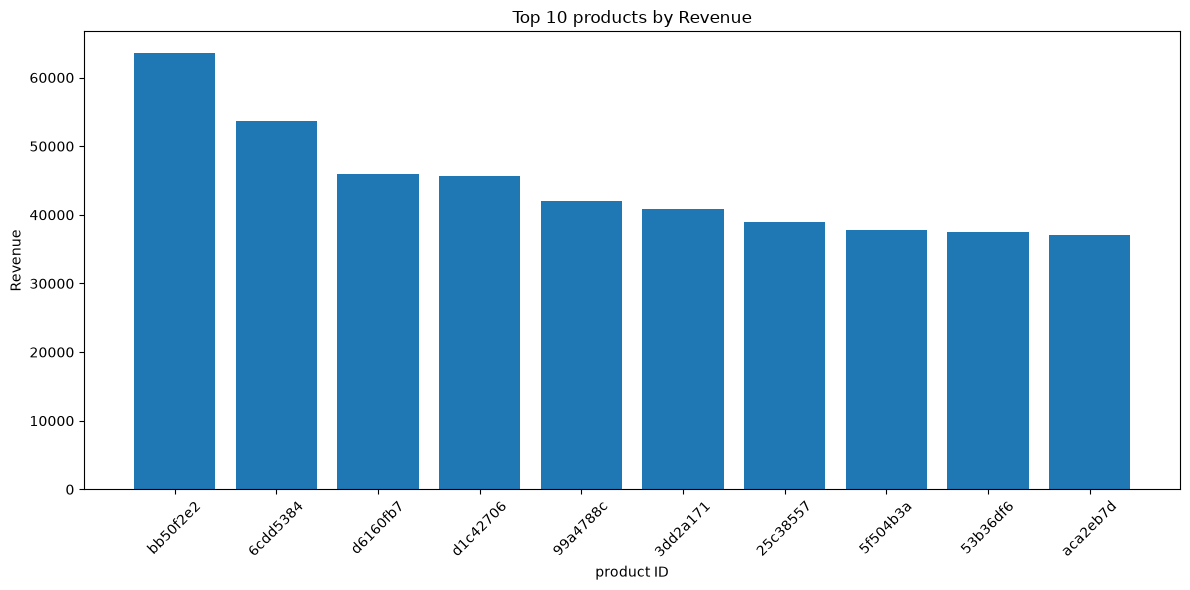

In [142]:
#creating top 10 visualization
# create short product IDs for visualization

top_10_products["product"] = (
    top_10_products["product_id"].str[:8]
)

#plot top 10 products by revenue
plt.figure(figsize=(12, 6))
plt.bar(
    top_10_products["product"],
    top_10_products["Total_Revenue"]
)
plt.title("Top 10 products by Revenue")
plt.xlabel("product ID")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [143]:
#bottom 10 products by revenue

bottom_10_prodcuts = (
    product_sales
    .groupby("product_id")
    .agg(
        Total_Revenue=("revenue","sum"),
        orders=("order_id","nunique")
    )
    .reset_index()
    .sort_values("Total_Revenue",ascending=True)
)

bottom_10_prodcuts = bottom_10_prodcuts.head(10)
bottom_10_prodcuts

,product_id,Total_Revenue,orders
9036,46fce52cef5caa7cc225a5531c946c8b,2.20,1
6250,310dc32058903b6416c71faff132df9e,2.29,1
17371,8a3254bee785a526d548a81a9bc3c9be,2.55,3
13154,680cc8535be7cc69544238c1d6a83fe8,2.90,1
5953,2e8316b31db34314f393806fd7b6e185,2.99,1
1913,0eeeb45e2f5911fd44282e5bb0c624ff,3.85,1
30074,eee2fb3dceb9ffd8a99dd4bc4b7e860a,3.90,1
24503,c2fb26742f8484dbfe9a8d70bdc54025,3.90,1
16594,836c4b48c2b383bb38bb5788f828c596,3.90,1
27797,dc9f66a56b89e4278d921898a861a29a,3.90,1


In [144]:
bottom_10_prodcuts = bottom_10_prodcuts.merge(
    products[["product_id","product_category_name"]],
    on="product_id",
    how="left"
)
bottom_10_prodcuts

,product_id,Total_Revenue,orders,product_category_name
0,46fce52cef5caa7cc225a5531c946c8b,2.20,1,beleza_saude
1,310dc32058903b6416c71faff132df9e,2.29,1,papelaria
2,8a3254bee785a526d548a81a9bc3c9be,2.55,3,construcao_ferramentas_construcao
3,680cc8535be7cc69544238c1d6a83fe8,2.90,1,pet_shop
4,2e8316b31db34314f393806fd7b6e185,2.99,1,papelaria
5,0eeeb45e2f5911fd44282e5bb0c624ff,3.85,1,musica
6,eee2fb3dceb9ffd8a99dd4bc4b7e860a,3.90,1,informatica_acessorios
7,c2fb26742f8484dbfe9a8d70bdc54025,3.90,1,informatica_acessorios
8,836c4b48c2b383bb38bb5788f828c596,3.90,1,fashion_underwear_e_moda_praia
9,dc9f66a56b89e4278d921898a861a29a,3.90,1,NaN


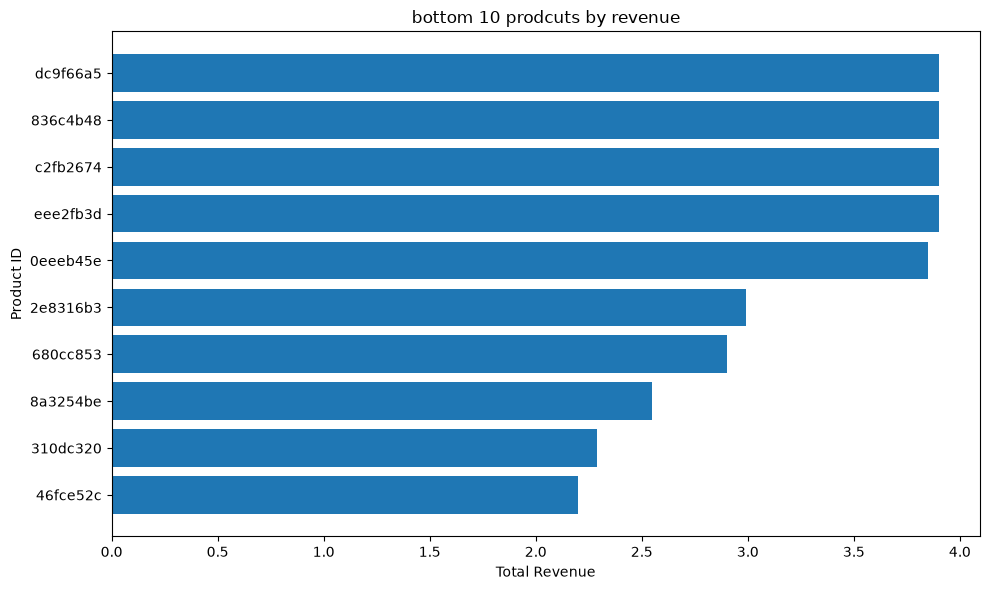

In [145]:
#bottom 10 products chart

plt.figure(figsize=(10,6))
plt.barh(
    bottom_10_prodcuts["product_id"].str[:8],
    bottom_10_prodcuts["Total_Revenue"]
)

plt.xlabel("Total Revenue")
plt.ylabel("Product ID")
plt.title("bottom 10 prodcuts by revenue")
plt.tight_layout()
plt.show()

In [146]:
#analyzing revenue by product category
category_revenue = (
    product_sales
    .groupby("product_category_name")
    .agg(
        total_revenue=("revenue","sum"),
        orders=("order_id","nunique")
    )
    .reset_index()
    .sort_values("total_revenue",ascending=False)
)

category_revenue.head(10)

,product_category_name,total_revenue,orders
11,beleza_saude,1233131.72,8647
66,relogios_presentes,1166176.98,5495
13,cama_mesa_banho,1023434.76,9272
32,esporte_lazer,954852.55,7530
44,informatica_acessorios,888724.61,6530
54,moveis_decoracao,711927.69,6307
72,utilidades_domesticas,615628.69,5743
26,cool_stuff,610204.10,3559
8,automotivo,578966.65,3810
12,brinquedos,471286.48,3804


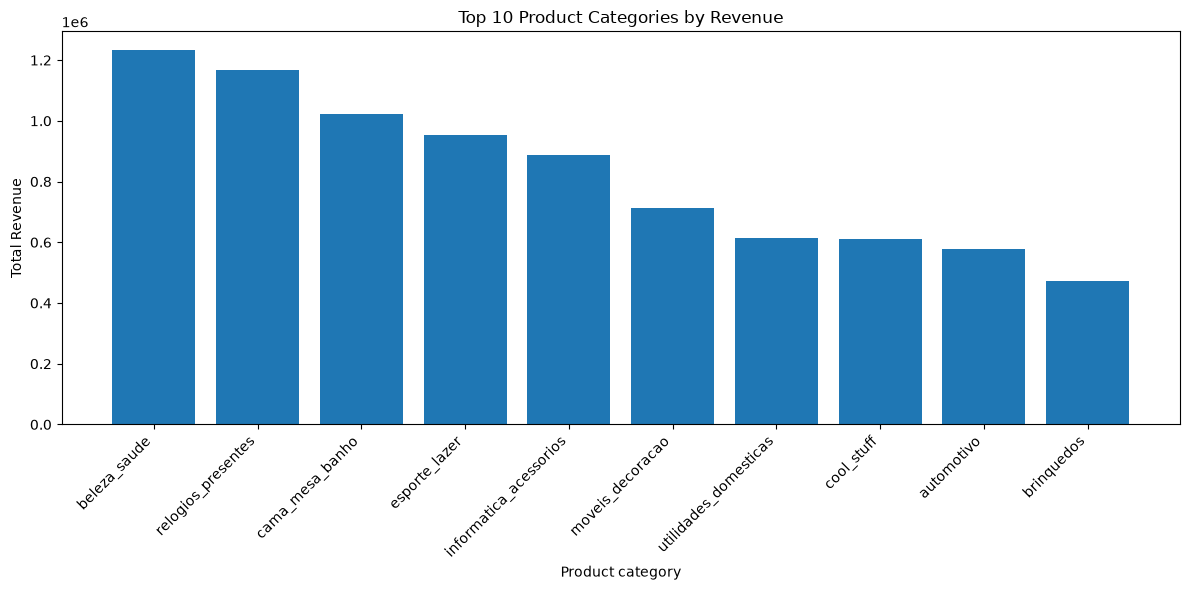

In [147]:
#category revenue chart 
top_10_categories = category_revenue.head(10)
plt.figure(figsize=(12,6))
plt.bar(
    top_10_categories["product_category_name"],
    top_10_categories["total_revenue"]
)
plt.xlabel("Product category")
plt.ylabel("Total Revenue")
plt.title("Top 10 Product Categories by Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [148]:
#Analyzing average order value(AOV) by category
category_aov = (
    product_sales
    .groupby("product_category_name")
    .agg(
        total_revenue=("revenue","sum"),
        orders=("order_id","nunique")
    )
    .reset_index()
)
category_aov["AOV"]=(
    category_aov["total_revenue"] / category_aov["orders"]
)
category_aov = category_aov.sort_values(
    "AOV",
    ascending=False
)
category_aov.head(10)


,product_category_name,total_revenue,orders,AOV
61,pcs,218684.14,177,1235.503616
64,portateis_casa_forno_e_cafe,46589.56,72,647.077222
29,eletrodomesticos_2,107953.95,227,475.568062
0,agro_industria_e_comercio,70566.10,177,398.678531
65,portateis_cozinha_e_preparadores_de_alimentos,3933.63,13,302.586923
45,instrumentos_musicais,184315.74,611,301.662422
31,eletroportateis,182754.12,609,300.088867
71,telefonia_fixa,55315.21,212,260.920802
25,construcao_ferramentas_seguranca,38773.22,159,243.856730
19,climatizacao,53323.56,246,216.762439


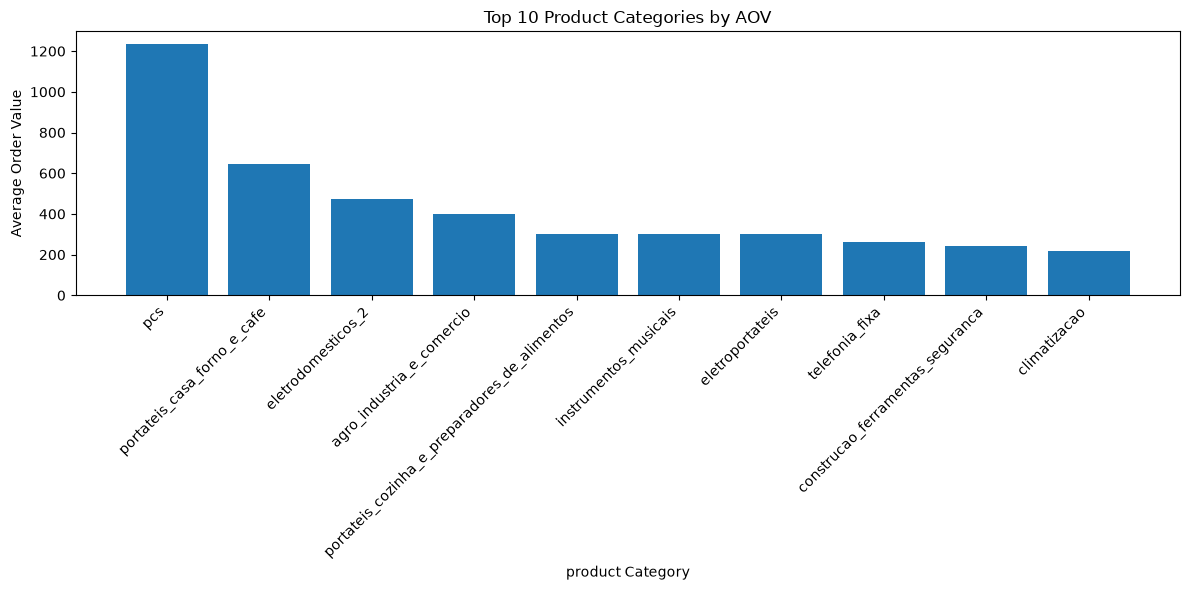

In [149]:
#creating AOV by category chart
#Top 10 categories by AOV

top_10_aov = category_aov.head(10)
plt.figure(figsize=(12,6))
plt.bar(
    top_10_aov["product_category_name"],
    top_10_aov["AOV"]
)
plt.xlabel("product Category")
plt.ylabel("Average Order Value")
plt.title("Top 10 Product Categories by AOV")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [150]:
#Delivery performance analysis
delivery_data = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna()) &
    (orders["order_estimated_delivery_date"].notna())
].copy()

delivery_data["order_delivered_customer_date"] = pd.to_datetime(
    delivery_data["order_delivered_customer_date"]
)

delivery_data["order_estimated_delivery_date"] = pd.to_datetime(
    delivery_data["order_estimated_delivery_date"]
)

delivery_data["delivery_days"] = (
    delivery_data["order_delivered_customer_date"] - pd.to_datetime(delivery_data["order_purchase_timestamp"])
).dt.days

delivery_data["is_late"] = (
    delivery_data["order_delivered_customer_date"] > delivery_data["order_estimated_delivery_date"]
)

delivery_data[[
    "delivery_days",
    "is_late"
]].describe()

,delivery_days
count,96470.000000
mean,12.093604
std,9.551380
min,0.000000
25%,6.000000
50%,10.000000
75%,15.000000
max,209.000000


In [151]:
#late delivery analysis
late_orders = delivery_data["is_late"].sum()
total_delivered = len(delivery_data)
late_delivery_rate = (
    late_orders/total_delivered
) * 100

print("Late Orders:",late_orders)
print("Total Delivered Orders:",total_delivered)
print("Late delivery Rate:",round(late_delivery_rate, 2), "%")

Late Orders: 7826
Total Delivered Orders: 96470
Late delivery Rate: 8.11 %


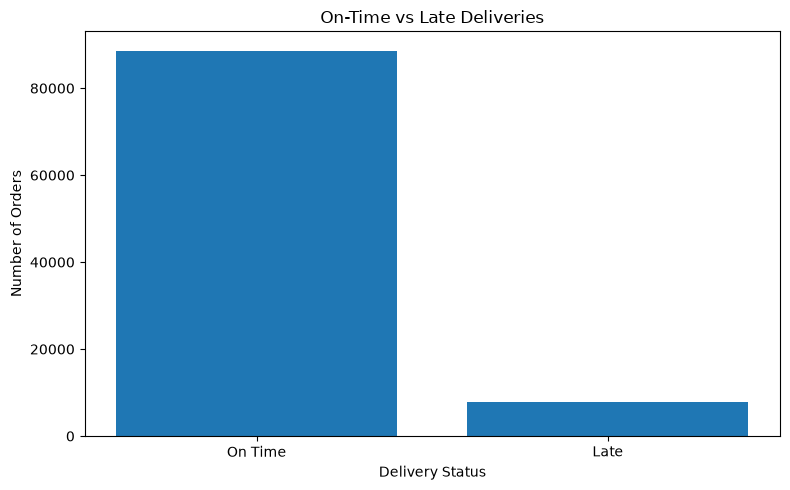

In [152]:
#Delivery status distribution
delivery_status = delivery_data["is_late"].value_counts()
labels = ["On Time","Late"]
values = [
    delivery_status.get(False, 0),
    delivery_status.get(True, 0)
]
plt.figure(figsize=(8,5))
plt.bar(labels,values)
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.title("On-Time vs Late Deliveries")
plt.tight_layout()
plt.show()

In [153]:
#Average delivery time by delivery status

delivery_time_comparison = (
    delivery_data
    .groupby("is_late")["delivery_days"]
    .mean()
    .reset_index()
)

delivery_time_comparison["is_late"] = (
    delivery_time_comparison["is_late"]
    .map({False: "On Time", True: "Late"})
)

delivery_time_comparison.columns = [
    "Delivery status",
    "Average Delivery Days" 
]

delivery_time_comparison["Average Delivery days"] = (
    delivery_time_comparison["Average Delivery Days"].round(2)
)

delivery_time_comparison

,Delivery status,Average Delivery Days,Average Delivery days
0,On Time,10.419329,10.42
1,Late,31.057884,31.06


In [154]:
#Removing duplicate/misspelled column
delivery_time_comparison = delivery_time_comparison.drop(
    columns=["Average Delivery days"]
)
delivery_time_comparison

,Delivery status,Average Delivery Days
0,On Time,10.419329
1,Late,31.057884


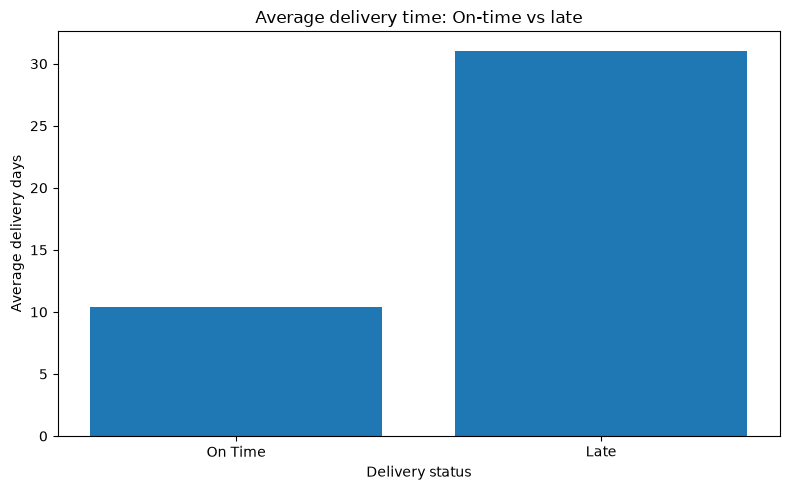

In [155]:
#Average Delivery time chart
plt.figure(figsize=(8,5))
plt.bar(
    delivery_time_comparison["Delivery status"],
    delivery_time_comparison["Average Delivery Days"]
)
plt.xlabel("Delivery status")
plt.ylabel("Average delivery days")
plt.title("Average delivery time: On-time vs late")
plt.tight_layout()
plt.show()

In [156]:
#order status distribution
order_status_counts = (
    orders["order_status"]
    .value_counts()
    .reset_index()
)
order_status_counts.columns = [
    "order status",
    "order count"
]
order_status_counts

,order status,order count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


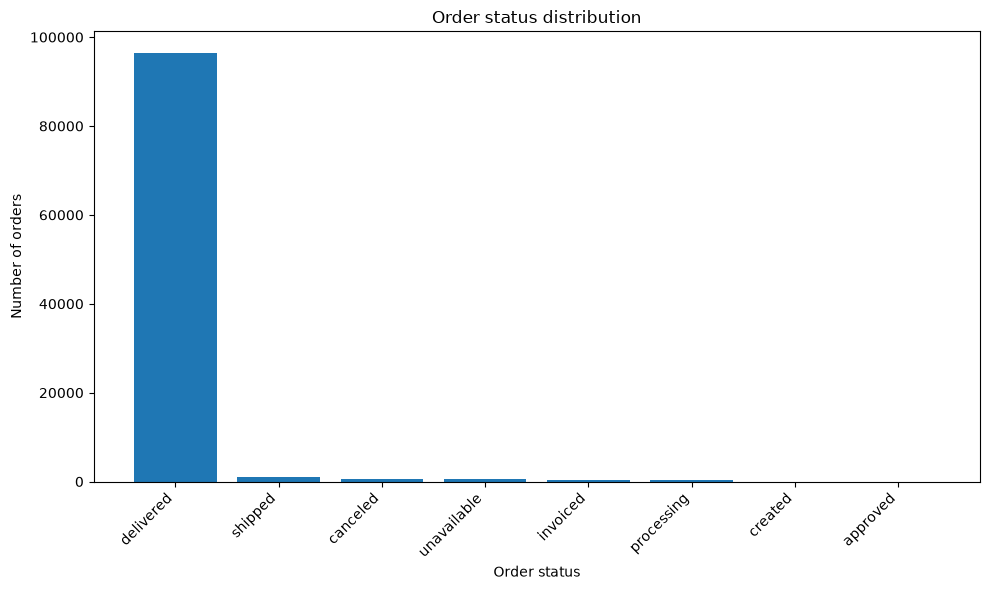

In [157]:
#order status chart
plt.figure(figsize=(10,6))
plt.bar(
    order_status_counts["order status"],
    order_status_counts["order count"]
)
plt.xlabel("Order status")
plt.ylabel("Number of orders")
plt.title("Order status distribution")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [158]:
#cancellation rate analysis
canceled_orders= (
    orders["order_status"] == "canceled"
).sum()
total_orders = len(orders)
cancellation_rate = (
    canceled_orders/total_orders
) * 100
print("canceled orders:",canceled_orders)
print("Total Orders:", total_orders)
print("Cancellation Rate:", round(cancellation_rate, 2), "%")

canceled orders: 625
Total Orders: 99441
Cancellation Rate: 0.63 %


In [159]:
#customer review score distribution
review_scores = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

review_scores.columns = [
    "Review Score",
    "Review Count"
]
review_scores

,Review Score,Review Count
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328


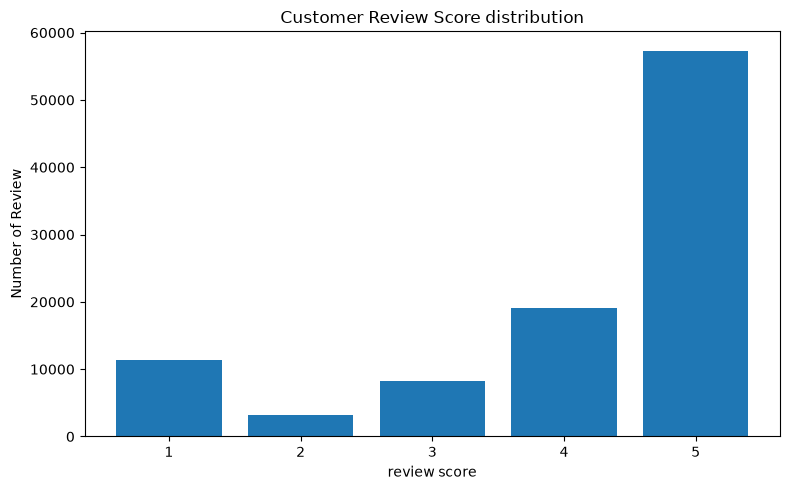

In [160]:
#Customer review score chart
plt.figure(figsize=(8,5))
plt.bar(
    review_scores["Review Score"],
    review_scores["Review Count"]
)
plt.xlabel("review score")
plt.ylabel("Number of Review")
plt.title("Customer Review Score distribution")
plt.xticks([1, 2, 3, 4, 5])
plt. tight_layout()
plt.show()

In [161]:
#Average customer review score
average_review_score = reviews["review_score"].mean()
print(
    "Average Review Score:",
    round(average_review_score, 2)
)

Average Review Score: 4.09


In [162]:
#Positive or negative review analysis
total_reviews = len(reviews)
positive_reviews = (
    reviews["review_score"] >= 4
).sum()

negative_reviews = (
    reviews["review_score"] <= 2
).sum()

positive_percentage = (
    positive_reviews/total_reviews
) * 100

negative_percentage = (
    negative_reviews / total_reviews
) * 100

print("Total Reviews:", total_reviews)
print("Positive Reviews:", positive_reviews)
print("Positive Review Percentage:", round(positive_percentage, 2), "%")
print("negative_reviews:", negative_reviews)
print("Negative Review Percentage:", round(negative_percentage, 2), "%")

Total Reviews: 99224
Positive Reviews: 76470
Positive Review Percentage: 77.07 %
negative_reviews: 14575
Negative Review Percentage: 14.69 %


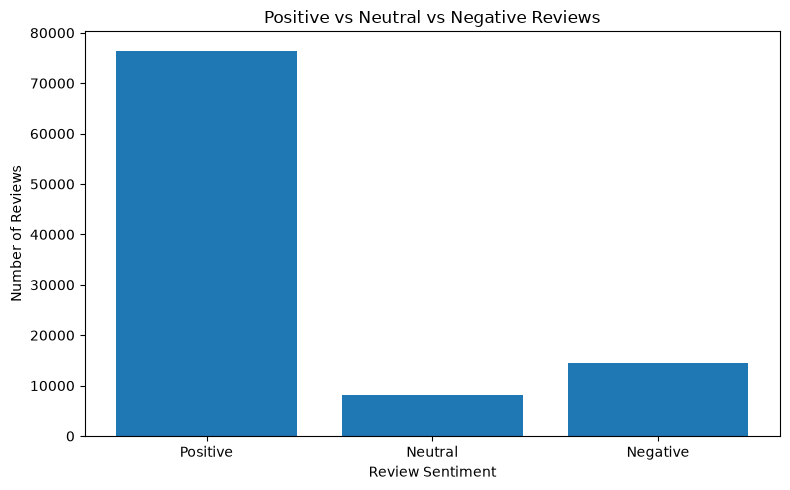

In [163]:
# Review sentiment chart

sentiment_labels = ["Positive", "Neutral", "Negative"]

sentiment_values = [
    positive_reviews,
    total_reviews - positive_reviews - negative_reviews,
    negative_reviews
]

plt.figure(figsize=(8, 5))

plt.bar(
    range(3),
    sentiment_values
)

plt.xticks(
    range(3),
    sentiment_labels
)

plt.xlabel("Review Sentiment")
plt.ylabel("Number of Reviews")
plt.title("Positive vs Neutral vs Negative Reviews")

plt.tight_layout()
plt.show()

In [164]:
#Freight cost analysis
freight_analysis = (
    order_items
    .agg(
        Total_Freight=("freight_value","sum"),
        Average_Freight=("freight_value","mean"),
        Average_product_price=("price","mean")
    )
)

freight_analysis=freight_analysis.round(2)
freight_analysis

,freight_value,price
Total_Freight,2251909.54,NaN
Average_Freight,19.99,NaN
Average_product_price,NaN,120.65


In [165]:
#clean freight cost analysis
freight_analysis = pd.DataFrame({
    "Metric": [
        "Total Freight",
        "Averge Freight",
        "Average Product Price"
    ],
    "value": [
        order_items["freight_value"].sum(),
        order_items["freight_value"].mean(),
        order_items["price"].mean()
    ]
})
freight_analysis["value"] = freight_analysis["value"].round(2)

In [166]:
print(freight_analysis)

                  Metric       value
0          Total Freight  2251909.54
1         Averge Freight       19.99
2  Average Product Price      120.65


In [167]:
freight_by_category = (
    product_sales
    .groupby("product_category_name")
    .agg(
        Total_freight=("freight_value","sum"),
        Average_freight=("freight_value","mean"),
        Average_product_price=("price","mean"),
        orders=("order_id","nunique")
    )
    .reset_index()
)
freight_by_category["freight_to_price_%"] = (
    freight_by_category["Average_freight"] / freight_by_category["Average_product_price"] * 100
)
freight_by_category["freight_to_price_%"] = (
    freight_by_category["freight_to_price_%"].round(2)
)

freight_by_category = freight_by_category.sort_values(
    "freight_to_price_%",
    ascending=False
)
freight_by_category.head(10)

,product_category_name,Total_freight,Average_freight,Average_product_price,orders,freight_to_price_%
15,casa_conforto_2,410.31,13.677000,25.342333,24,53.97
41,flores,488.87,14.814242,33.637576,29,44.04
52,moveis_colchao_e_estofado,1581.37,42.739730,116.848108,37,36.58
6,artigos_de_natal,3190.91,21.272733,58.252267,125,36.52
42,fraldas_higiene,545.40,14.740541,40.561892,25,36.34
17,cds_dvds_musicais,224.99,16.070714,52.142857,12,30.82
68,sinalizacao_e_seguranca,6477.54,32.880914,108.198223,138,30.39
30,eletronicos,45679.16,16.738424,56.813459,2517,29.46
2,alimentos_bebidas,4394.89,16.337881,55.549740,221,29.41
27,dvds_blu_ray,1227.25,20.118852,74.468689,56,27.02


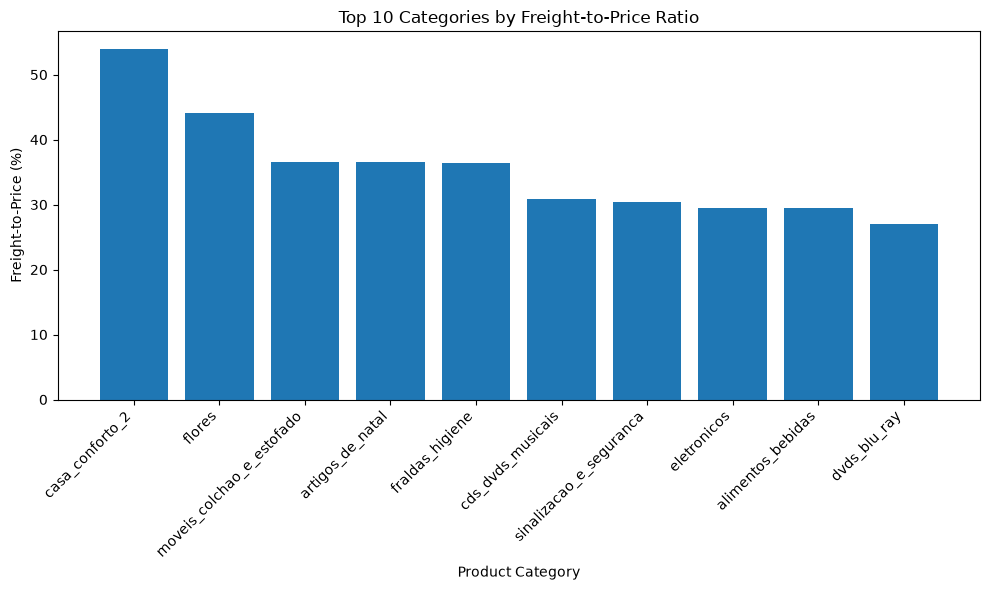

In [168]:

top_freight_categories = freight_by_category.head(10)

plt.figure(figsize=(10, 6))

plt.bar(
    top_freight_categories["product_category_name"],
    top_freight_categories["freight_to_price_%"]
)

plt.xlabel("Product Category")
plt.ylabel("Freight-to-Price (%)")
plt.title("Top 10 Categories by Freight-to-Price Ratio")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [169]:
#Payment method analysis
payment_method_analysis = (
    payments
    .groupby("payment_type")
    .agg(
        orders = ("order_id","nunique"),
        total_revenue=("payment_value","sum"),
        Average_Payment=("payment_value","mean")
    )
    .reset_index()
    .sort_values("total_revenue",ascending=False)
)
payment_method_analysis["total_revenue"] = payment_method_analysis["total_revenue"].round(2)
payment_method_analysis["Average_Payment"] = payment_method_analysis["Average_Payment"].round(2)
payment_method_analysis

,payment_type,orders,total_revenue,Average_Payment
1,credit_card,76505,12542084.19,163.32
0,boleto,19784,2869361.27,145.03
4,voucher,3866,379436.87,65.70
2,debit_card,1528,217989.79,142.57
3,not_defined,3,0.00,0.00


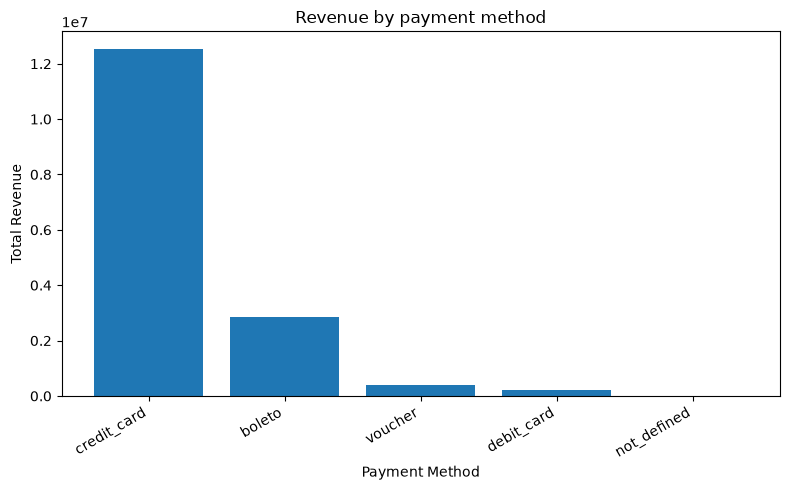

In [170]:
plt.figure(figsize=(8,5))
plt.bar(
    payment_method_analysis["payment_type"],
    payment_method_analysis["total_revenue"]
)
plt.xlabel("Payment Method")
plt.ylabel("Total Revenue")
plt.title("Revenue by payment method")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [171]:
#calculate monthly orders
monthly_orders = (
    orders
    .assign(
        order_purchase_timestamp=pd.to_datetime(
            orders["order_purchase_timestamp"]
        )
    )
    .groupby(
        orders["order_purchase_timestamp"].dt.to_period("M")
    )
    .agg(
        Orders=("order_id", "nunique")
    )
    .reset_index()
)

monthly_orders["order_purchase_timestamp"] = (
    monthly_orders["order_purchase_timestamp"].astype(str)
)

monthly_orders

,order_purchase_timestamp,Orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


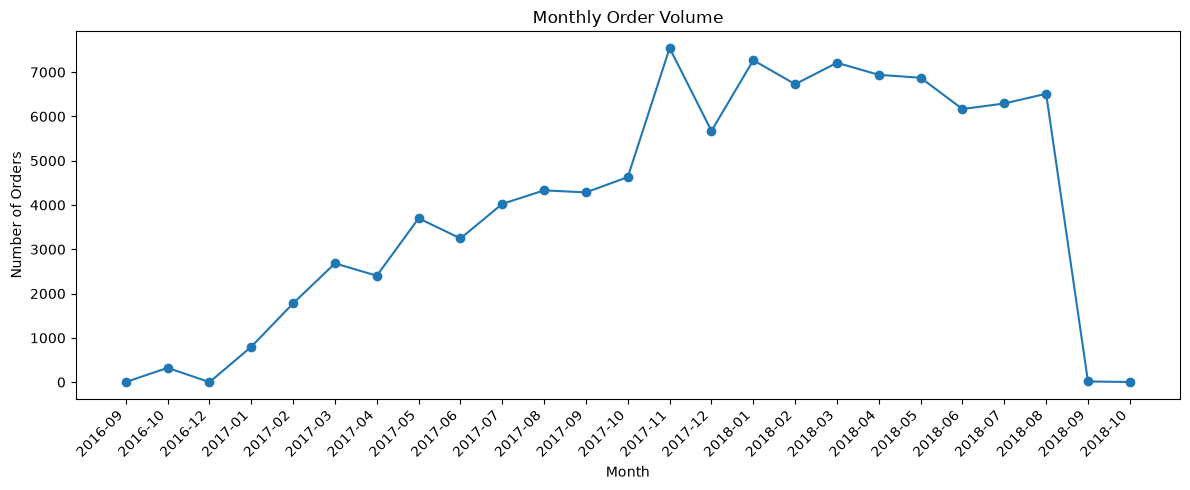

In [172]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_orders["order_purchase_timestamp"],
    monthly_orders["Orders"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.title("Monthly Order Volume")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [173]:
#Average order value trend
monthly_aov = (
    order_sales
    .groupby("month")
    .agg(
        Total_Revenue=("revenue", "sum"),
        Orders=("order_id", "nunique")
    )
    .reset_index()
)

monthly_aov["AOV"] = (
    monthly_aov["Total_Revenue"] / monthly_aov["Orders"]
)

monthly_aov["AOV"] = monthly_aov["AOV"].round(2)

monthly_aov

,month,Total_Revenue,Orders,AOV
0,2016-09,267.36,3,89.12
1,2016-10,49507.66,308,160.74
2,2016-12,10.90,1,10.90
3,2017-01,120312.87,789,152.49
4,2017-02,247303.02,1733,142.70
5,2017-03,374344.30,2641,141.74
6,2017-04,359927.23,2391,150.53
7,2017-05,506071.14,3660,138.27
8,2017-06,433038.60,3217,134.61
9,2017-07,498031.48,3969,125.48


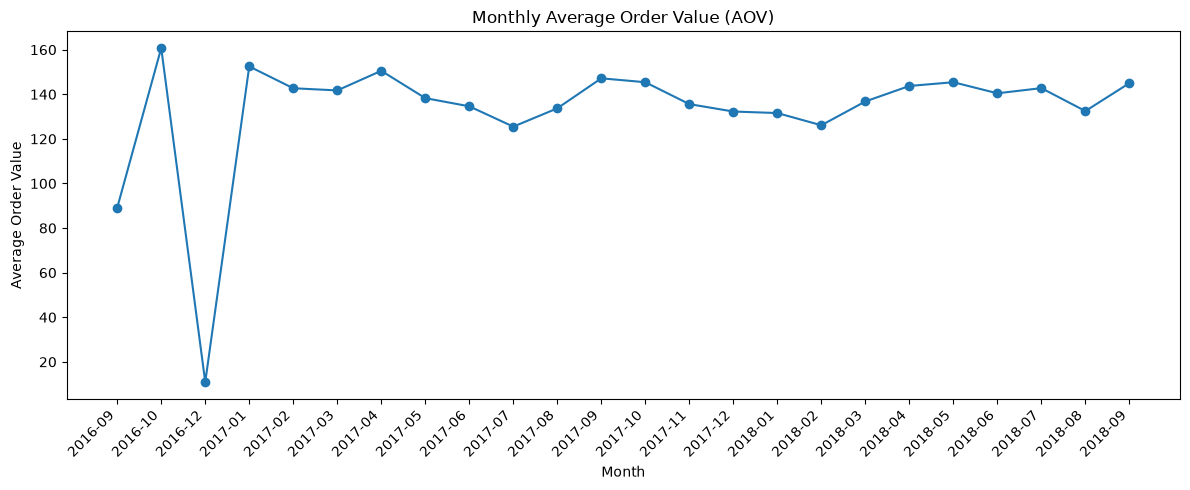

In [174]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_aov["month"].astype(str),
    monthly_aov["AOV"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Average Order Value")
plt.title("Monthly Average Order Value (AOV)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [175]:
#customer purchase frequency
customer_frequency = (
    orders
    .merge(
        customers[["customer_id", "customer_unique_id"]],
        on="customer_id",
        how="left"
    )
    .groupby("customer_unique_id")
    .agg(
        Total_Orders=("order_id", "nunique")
    )
    .reset_index()
)

customer_frequency["Total_Orders"].describe()

count    96096.000000
mean         1.034809
std          0.214384
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         17.000000
Name: Total_Orders, dtype: float64

In [176]:
frequency_distribution = (
    customer_frequency["Total_Orders"]
    .value_counts()
    .sort_index()
)

frequency_distribution

Total_Orders
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

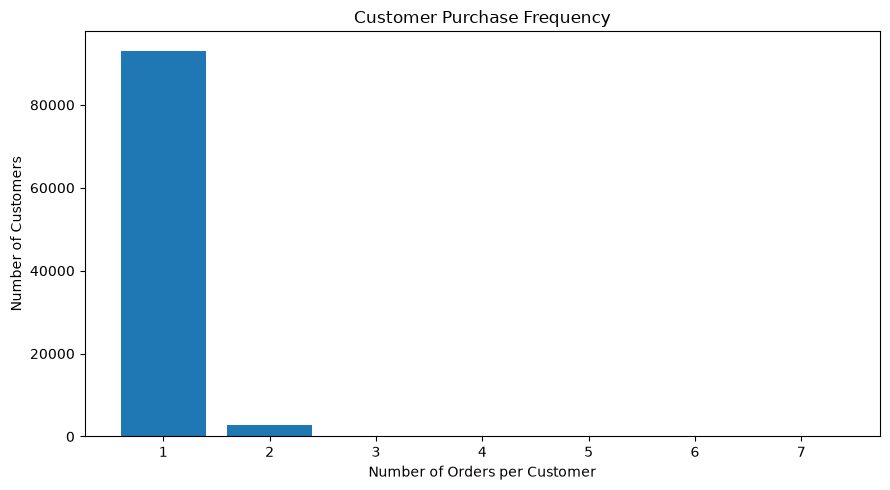

In [177]:
frequency_chart = (
    frequency_distribution[
        frequency_distribution.index <= 7
    ]
)

plt.figure(figsize=(9, 5))

plt.bar(
    frequency_chart.index.astype(str),
    frequency_chart.values
)

plt.xlabel("Number of Orders per Customer")
plt.ylabel("Number of Customers")
plt.title("Customer Purchase Frequency")

plt.tight_layout()
plt.show()

In [178]:
#One time vs repeat customer revenue
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

customer_order_summary = (
    delivered_orders
    .merge(
        customers[["customer_id", "customer_unique_id"]],
        on="customer_id",
        how="left"
    )
    .merge(
        order_items[["order_id", "price"]],
        on="order_id",
        how="left"
    )
    .groupby("customer_unique_id")
    .agg(
        Total_Orders=("order_id", "nunique"),
        Total_Revenue=("price", "sum")
    )
    .reset_index()
)

customer_order_summary["Customer_Type"] = (
    customer_order_summary["Total_Orders"]
    .apply(lambda x: "One-Time" if x == 1 else "Repeat")
)

customer_type_summary = (
    customer_order_summary
    .groupby("Customer_Type")
    .agg(
        Customers=("customer_unique_id", "count"),
        Total_Revenue=("Total_Revenue", "sum")
    )
    .reset_index()
)

customer_type_summary["Revenue_Share_%"] = (
    customer_type_summary["Total_Revenue"]
    / customer_type_summary["Total_Revenue"].sum()
    * 100
)

customer_type_summary["Total_Revenue"] = (
    customer_type_summary["Total_Revenue"].round(2)
)

customer_type_summary["Revenue_Share_%"] = (
    customer_type_summary["Revenue_Share_%"].round(2)
)

customer_type_summary

,Customer_Type,Customers,Total_Revenue,Revenue_Share_%
0,One-Time,90557,12493089.36,94.49
1,Repeat,2801,728408.75,5.51


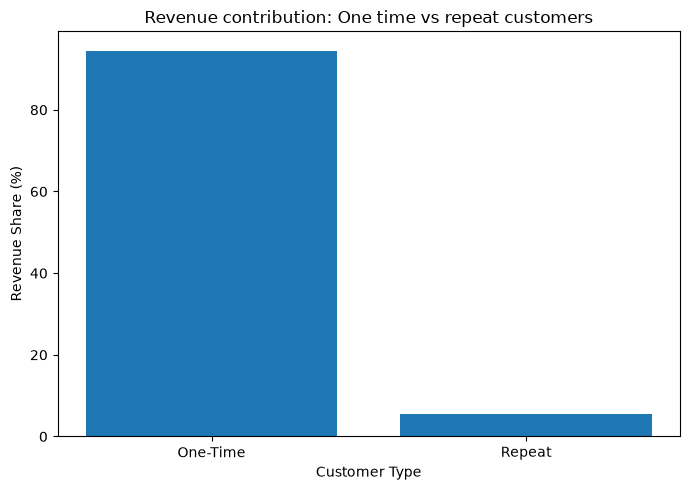

In [179]:
plt.figure(figsize=(7,5))
plt.bar(
    customer_type_summary["Customer_Type"],
    customer_type_summary["Revenue_Share_%"]
)
plt.xlabel("Customer Type")
plt.ylabel("Revenue Share (%)")
plt.title("Revenue contribution: One time vs repeat customers")
plt.tight_layout()
plt.show()

In [180]:
#Customer retention Rate
total_customers = customer_type_summary["Customers"].sum()
repeat_customers = customer_type_summary.loc[
    customer_type_summary["Customer_Type"] == "Repeat",
    "Customers"
].iloc[0]

retention_rate = (
    repeat_customers / total_customers
) * 100

print("Total Customers:", total_customers)
print("Repeat customers:", repeat_customers)
print("Customer retention rate:", round(retention_rate, 2), "%")

Total Customers: 93358
Repeat customers: 2801
Customer retention rate: 3.0 %


In [181]:
#Repeat purchase rate  by customer segment
customer_segment_frequency = (
    customer_order_summary
    .merge(
        rfm[["customer_unique_id", "Segment"]],
        on="customer_unique_id",
        how="left"
    )
)

customer_segment_frequency["Customer_Type"] = (
    customer_segment_frequency["Total_Orders"]
    .apply(lambda x: "Repeat" if x >= 2 else "One-Time")
)

segment_repeat_rate = (
    customer_segment_frequency
    .groupby("Segment")
    .agg(
        Customers=("customer_unique_id", "count"),
        Repeat_Customers=("Customer_Type", lambda x: (x == "Repeat").sum())
    )
    .reset_index()
)

segment_repeat_rate["Repeat_Rate_%"] = (
    segment_repeat_rate["Repeat_Customers"]
    / segment_repeat_rate["Customers"]
    * 100
)

segment_repeat_rate["Repeat_Rate_%"] = (
    segment_repeat_rate["Repeat_Rate_%"].round(2)
)

segment_repeat_rate = segment_repeat_rate.sort_values(
    "Repeat_Rate_%",
    ascending=False
)

segment_repeat_rate

,Segment,Customers,Repeat_Customers,Repeat_Rate_%
2,Champions,6517,937,14.38
4,Loyal Customers,16023,876,5.47
1,Big Spenders,13782,465,3.37
0,At Risk,17660,523,2.96
3,Lost Customers,6082,0,0.00
5,New Customers,3020,0,0.00
6,Others,30274,0,0.00


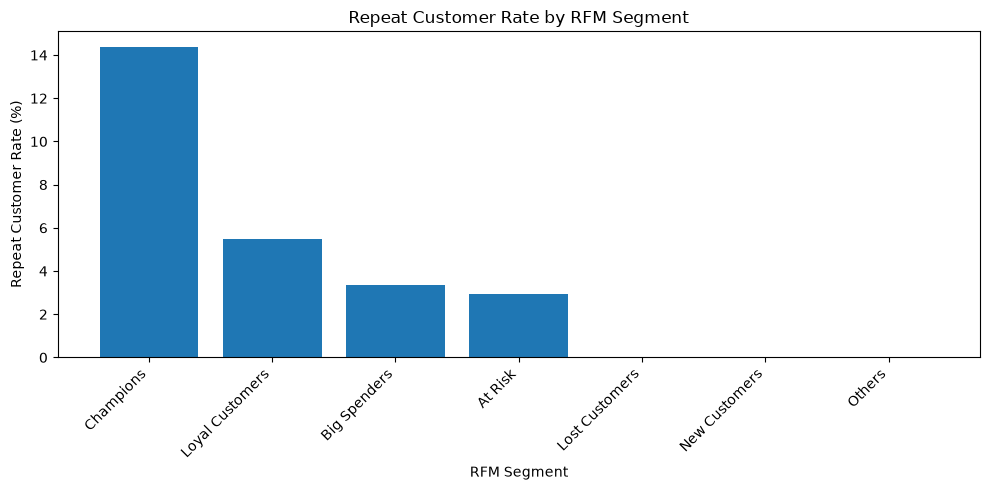

In [182]:
#visualize repeat rate by  RFM segment
plt.figure(figsize=(10, 5))
plt.bar(
    segment_repeat_rate["Segment"],
    segment_repeat_rate["Repeat_Rate_%"]
)

plt.xlabel("RFM Segment")
plt.ylabel("Repeat Customer Rate (%)")
plt.title("Repeat Customer Rate by RFM Segment")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [183]:
customer_order_summary["Total_Revenue"].describe()

count    93358.000000
mean       141.621480
std        215.694014
min          0.850000
25%         47.650000
50%         89.730000
75%        154.737500
max      13440.000000
Name: Total_Revenue, dtype: float64

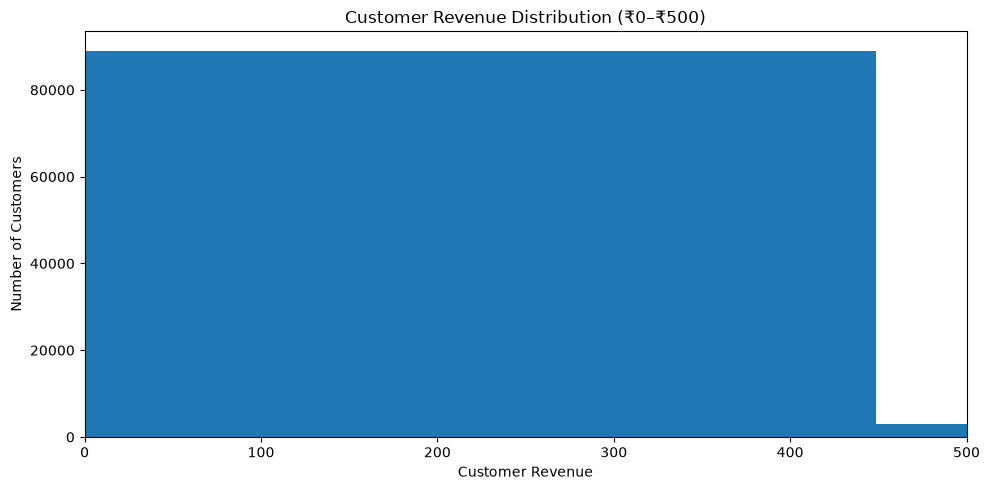

In [184]:
#customer revenue distribution chart
plt.figure(figsize=(10, 5))

plt.hist(
    customer_order_summary["Total_Revenue"],
    bins=30
)

plt.xlim(0, 500)
plt.xlabel("Customer Revenue")
plt.ylabel("Number of Customers")
plt.title("Customer Revenue Distribution (₹0–₹500)")
plt.tight_layout()
plt.show()

In [185]:
#revenue by RFM segment
segment_revenue_analysis = (
    customer_order_summary
    .merge(
        rfm[["customer_unique_id", "Segment"]],
        on="customer_unique_id",
        how="left"
    )
    .groupby("Segment")
    .agg(
        Customers=("customer_unique_id", "count"),
        Total_Revenue=("Total_Revenue", "sum"),
        Average_Revenue=("Total_Revenue", "mean")
    )
    .reset_index()
)

segment_revenue_analysis["Total_Revenue"] = (
    segment_revenue_analysis["Total_Revenue"].round(2)
)

segment_revenue_analysis["Average_Revenue"] = (
    segment_revenue_analysis["Average_Revenue"].round(2)
)

segment_revenue_analysis = segment_revenue_analysis.sort_values(
    "Total_Revenue",
    ascending=False
)

segment_revenue_analysis

,Segment,Customers,Total_Revenue,Average_Revenue
1,Big Spenders,13782,5561723.17,403.55
6,Others,30274,2324470.44,76.78
2,Champions,6517,1785868.12,274.03
4,Loyal Customers,16023,1522867.02,95.04
0,At Risk,17660,1337480.47,75.74
3,Lost Customers,6082,453382.26,74.54
5,New Customers,3020,235706.63,78.05


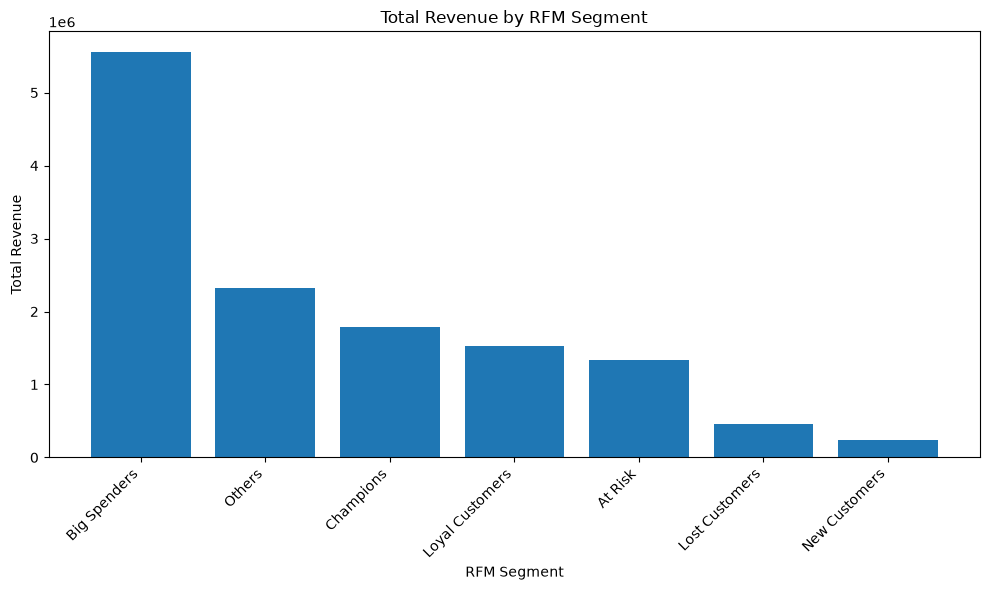

In [186]:
#total revenue by rfm segment
plt.figure(figsize=(10, 6))

plt.bar(
    segment_revenue_analysis["Segment"],
    segment_revenue_analysis["Total_Revenue"]
)

plt.xlabel("RFM Segment")
plt.ylabel("Total Revenue")
plt.title("Total Revenue by RFM Segment")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

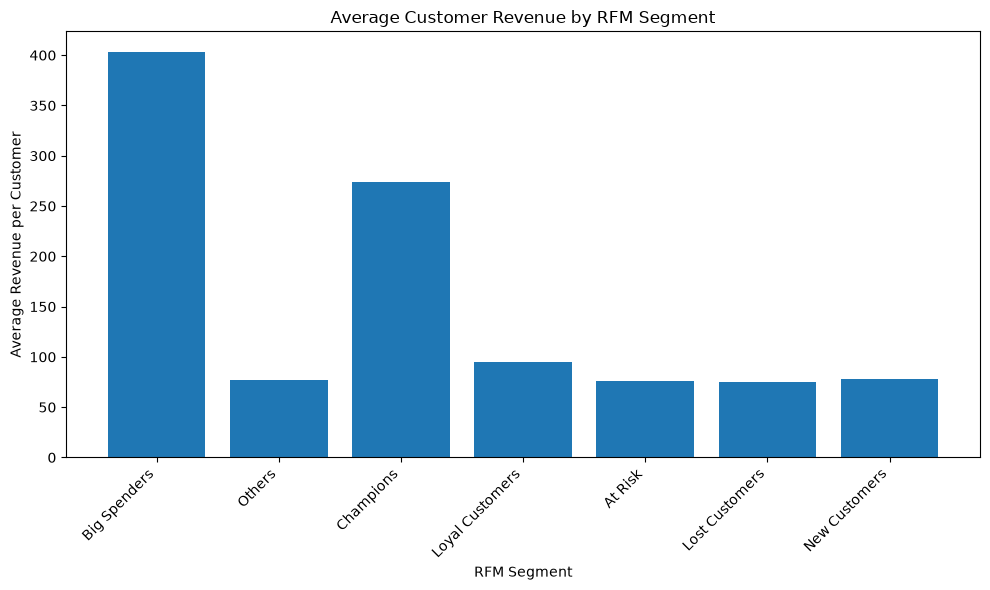

In [187]:
#Average revenue by RFM segment
plt.figure(figsize=(10, 6))

plt.bar(
    segment_revenue_analysis["Segment"],
    segment_revenue_analysis["Average_Revenue"]
)

plt.xlabel("RFM Segment")
plt.ylabel("Average Revenue per Customer")
plt.title("Average Customer Revenue by RFM Segment")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [188]:
#Revenue share by RFM segment
segment_revenue_analysis["Revenue_Share_%"] = (
    segment_revenue_analysis["Total_Revenue"]
    / segment_revenue_analysis["Total_Revenue"].sum()
    * 100
)

segment_revenue_analysis["Revenue_Share_%"] = (
    segment_revenue_analysis["Revenue_Share_%"].round(2)
)

segment_revenue_analysis[
    ["Segment", "Customers", "Total_Revenue", "Revenue_Share_%"]
]

,Segment,Customers,Total_Revenue,Revenue_Share_%
1,Big Spenders,13782,5561723.17,42.07
6,Others,30274,2324470.44,17.58
2,Champions,6517,1785868.12,13.51
4,Loyal Customers,16023,1522867.02,11.52
0,At Risk,17660,1337480.47,10.12
3,Lost Customers,6082,453382.26,3.43
5,New Customers,3020,235706.63,1.78


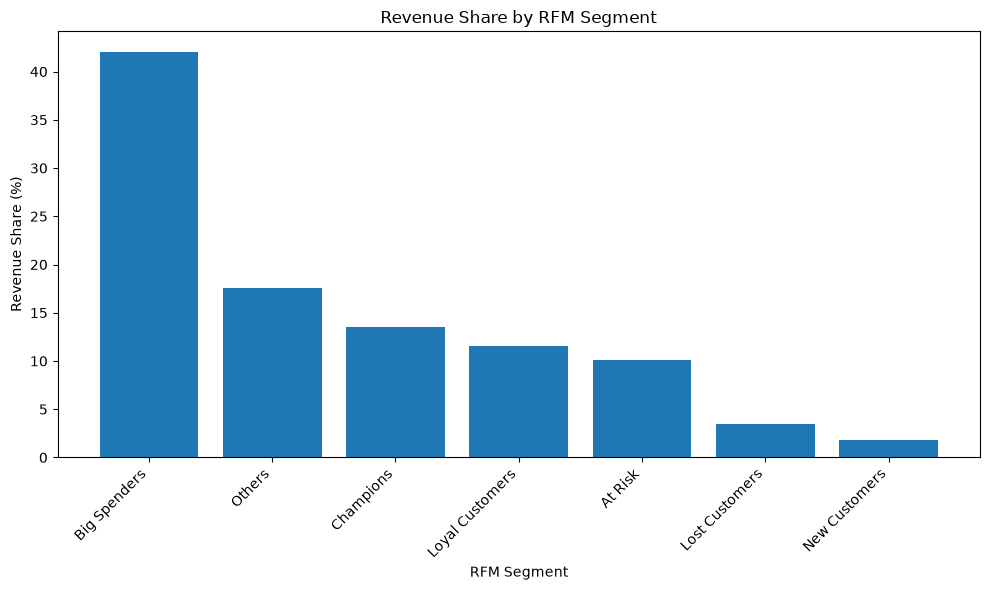

In [189]:
#Revenue share chart
plt.figure(figsize=(10, 6))

plt.bar(
    segment_revenue_analysis["Segment"],
    segment_revenue_analysis["Revenue_Share_%"]
)

plt.xlabel("RFM Segment")
plt.ylabel("Revenue Share (%)")
plt.title("Revenue Share by RFM Segment")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [190]:
#Monthly customer acquisition
customer_acquisition = (
    orders
    .merge(
        customers[["customer_id", "customer_unique_id"]],
        on="customer_id",
        how="left"
    )
)

customer_acquisition["order_purchase_timestamp"] = pd.to_datetime(
    customer_acquisition["order_purchase_timestamp"]
)

first_purchase = (
    customer_acquisition
    .groupby("customer_unique_id")["order_purchase_timestamp"]
    .min()
    .reset_index()
)

first_purchase["month"] = (
    first_purchase["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_new_customers = (
    first_purchase
    .groupby("month")
    .agg(
        New_Customers=("customer_unique_id", "count")
    )
    .reset_index()
)

monthly_new_customers

,month,New_Customers
0,2016-09,4
1,2016-10,321
2,2016-12,1
3,2017-01,764
4,2017-02,1752
5,2017-03,2636
6,2017-04,2352
7,2017-05,3596
8,2017-06,3139
9,2017-07,3894


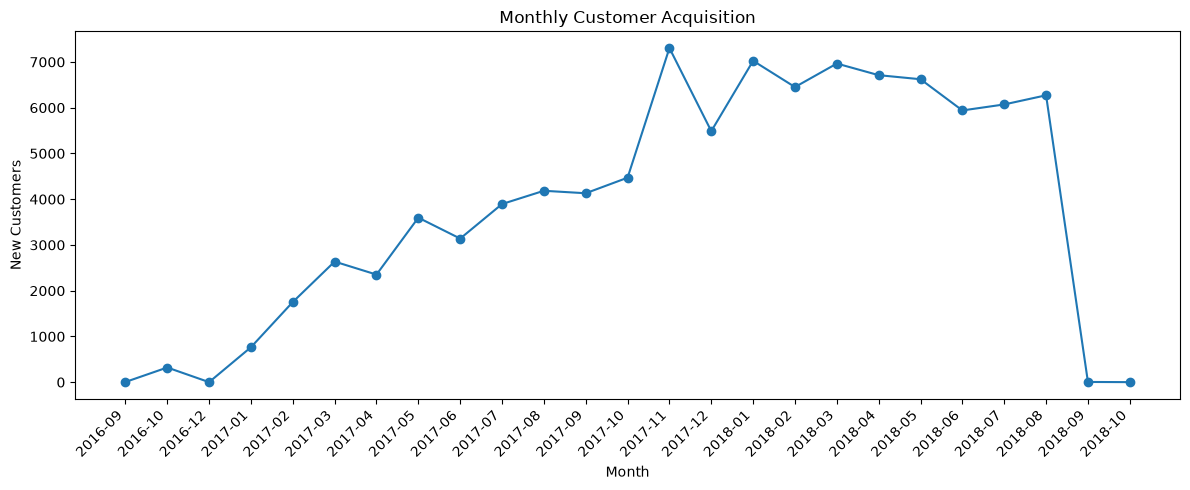

In [191]:
#Monthly customer acquisition chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_new_customers["month"].astype(str),
    monthly_new_customers["New_Customers"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("New Customers")
plt.title("Monthly Customer Acquisition")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [192]:
#Customer Lifetime Value (CLV) Proxy
customer_clv = (
    customer_order_summary[
        ["customer_unique_id", "Total_Orders", "Total_Revenue"]
    ]
    .copy()
)

customer_clv["CLV_Proxy"] = customer_clv["Total_Revenue"]

customer_clv = customer_clv.sort_values(
    "CLV_Proxy",
    ascending=False
)

customer_clv.head(10)

,customer_unique_id,Total_Orders,Total_Revenue,CLV_Proxy
3724,0a0a92112bd4c708ca5fde585afaa872,1,13440.0,13440.0
79636,da122df9eeddfedc1dc1f5349a1a690c,2,7388.0,7388.0
43168,763c8b1c9c68a0229c42c9fc6f662b93,1,7160.0,7160.0
80463,dc4802a71eae9be1dd28f5d788ceb526,1,6735.0,6735.0
25436,459bef486812aa25204be022145caa62,1,6729.0,6729.0
93081,ff4159b92c40ebe40454e3e6a7c35ed6,1,6499.0,6499.0
23411,4007669dec559734d6f53e029e360987,1,5934.6,5934.6
87148,eebb5dda148d3893cdaf5b5ca3040ccb,1,4690.0,4690.0
26640,48e1ac109decbb87765a3eade6854098,1,4590.0,4590.0
59163,a229eba70ec1c2abef51f04987deb7a5,1,4400.0,4400.0


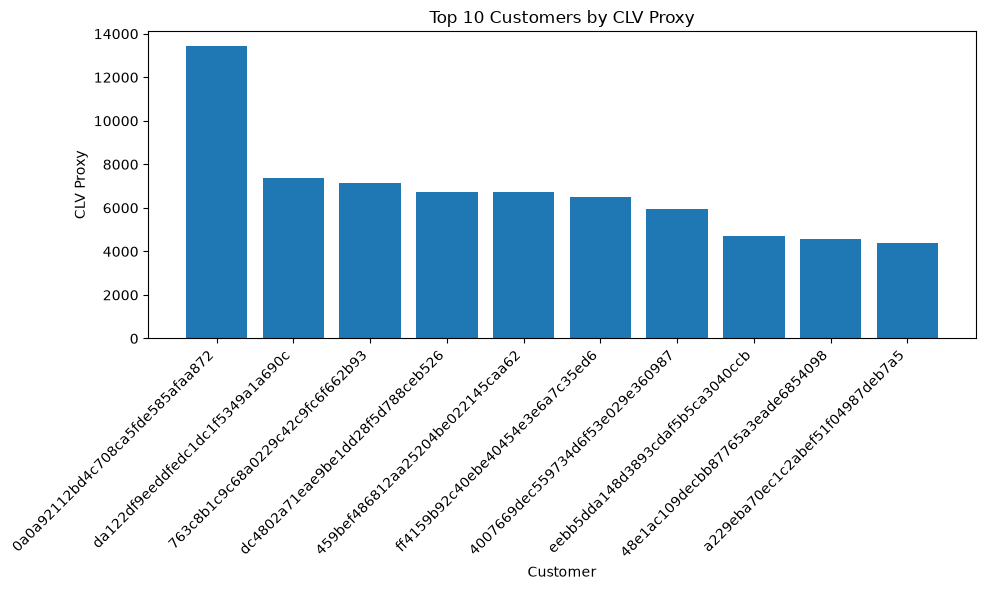

In [193]:
#Top 10 Customers by CLV Proxy
top_10_clv = customer_clv.head(10)

plt.figure(figsize=(10, 6))

plt.bar(
    top_10_clv["customer_unique_id"].astype(str),
    top_10_clv["CLV_Proxy"]
)

plt.xlabel("Customer")
plt.ylabel("CLV Proxy")
plt.title("Top 10 Customers by CLV Proxy")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

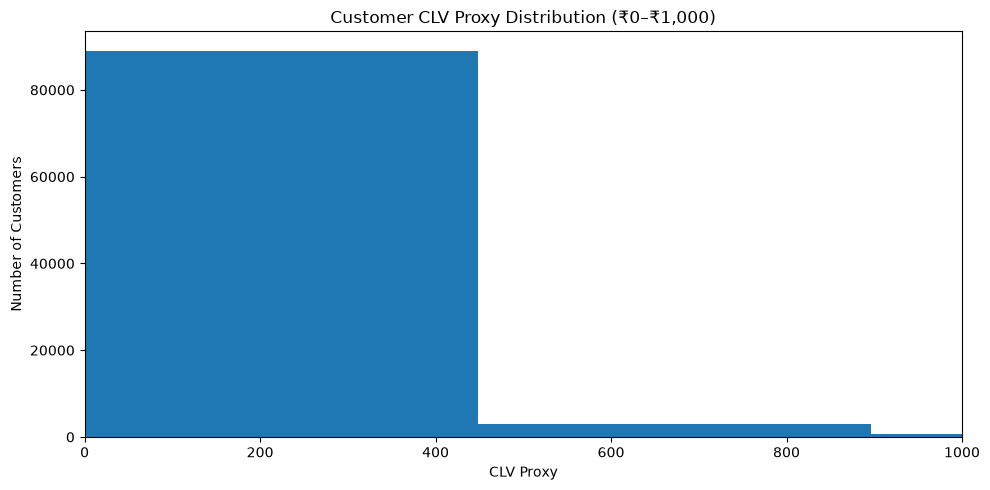

In [194]:
#CLV proxy distribution
plt.figure(figsize=(10, 5))

plt.hist(
    customer_clv["CLV_Proxy"],
    bins=30
)

plt.xlim(0, 1000)

plt.xlabel("CLV Proxy")
plt.ylabel("Number of Customers")
plt.title("Customer CLV Proxy Distribution (₹0–₹1,000)")

plt.tight_layout()
plt.show()

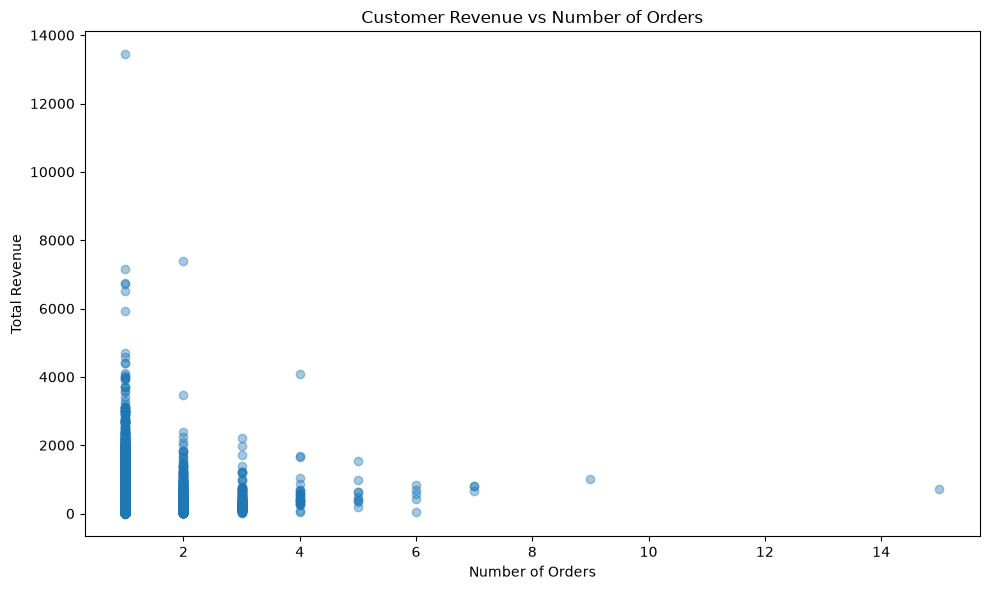

In [195]:
#Customer revenue vs number of orders
plt.figure(figsize=(10, 6))

plt.scatter(
    customer_order_summary["Total_Orders"],
    customer_order_summary["Total_Revenue"],
    alpha=0.4
)

plt.xlabel("Number of Orders")
plt.ylabel("Total Revenue")
plt.title("Customer Revenue vs Number of Orders")

plt.tight_layout()
plt.show()

In [196]:
#Correlation Between Orders and Revenue
customer_order_summary[
    ["Total_Orders", "Total_Revenue"]
].corr()

,Total_Orders,Total_Revenue
Total_Orders,1.000000,0.105775
Total_Revenue,0.105775,1.000000


In [197]:
#verage Revenue per Order by Customer Type
customer_type_aov = (
    customer_order_summary
    .groupby("Customer_Type")
    .agg(
        Customers=("customer_unique_id", "count"),
        Total_Revenue=("Total_Revenue", "sum"),
        Total_Orders=("Total_Orders", "sum")
    )
    .reset_index()
)

customer_type_aov["Revenue_per_Order"] = (
    customer_type_aov["Total_Revenue"]
    / customer_type_aov["Total_Orders"]
)

customer_type_aov["Revenue_per_Order"] = (
    customer_type_aov["Revenue_per_Order"].round(2)
)

customer_type_aov

,Customer_Type,Customers,Total_Revenue,Total_Orders,Revenue_per_Order
0,One-Time,90557,12493089.36,90557,137.96
1,Repeat,2801,728408.75,5921,123.02


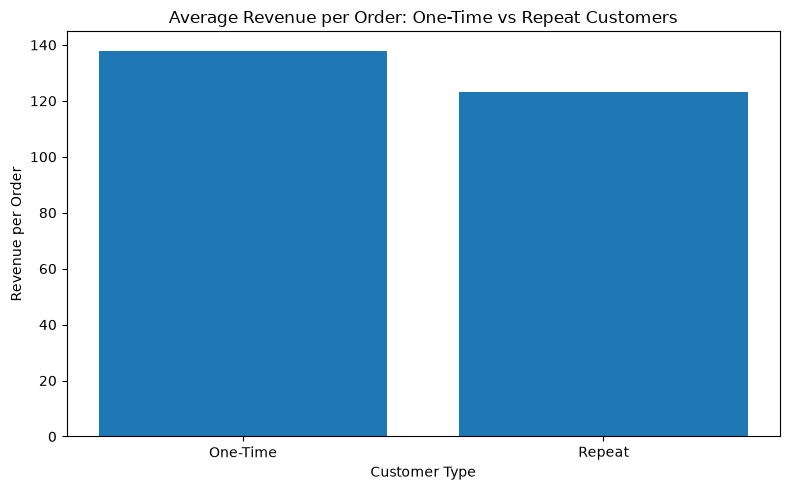

In [198]:
#customer type revenue comparison
plt.figure(figsize=(8, 5))

plt.bar(
    customer_type_aov["Customer_Type"],
    customer_type_aov["Revenue_per_Order"]
)

plt.xlabel("Customer Type")
plt.ylabel("Revenue per Order")
plt.title("Average Revenue per Order: One-Time vs Repeat Customers")

plt.tight_layout()
plt.show()

In [199]:
#Payment installment analysis
installment_analysis = (
    payments
    .groupby("payment_installments")
    .agg(
        Orders=("order_id","nunique"),
        total_revenue=("payment_value","sum"),
        Average_payment=("payment_value","mean")
    )
    .reset_index()
    .sort_values("payment_installments")
)
installment_analysis["total_revenue"] = (
    installment_analysis["total_revenue"].round(2)
)
installment_analysis["Average_payment"]=(
    installment_analysis["Average_payment"].round(2)
)
installment_analysis

,payment_installments,Orders,total_revenue,Average_payment
0,0,2,188.63,94.32
1,1,49060,5907233.36,112.42
2,2,12389,1579283.03,127.23
3,3,10443,1491103.80,142.54
4,4,7088,1163907.61,163.98
5,5,5234,961174.30,183.47
6,6,3916,822611.81,209.85
7,7,1623,305157.39,187.67
8,8,4253,1313423.34,307.74
9,9,644,131015.92,203.44


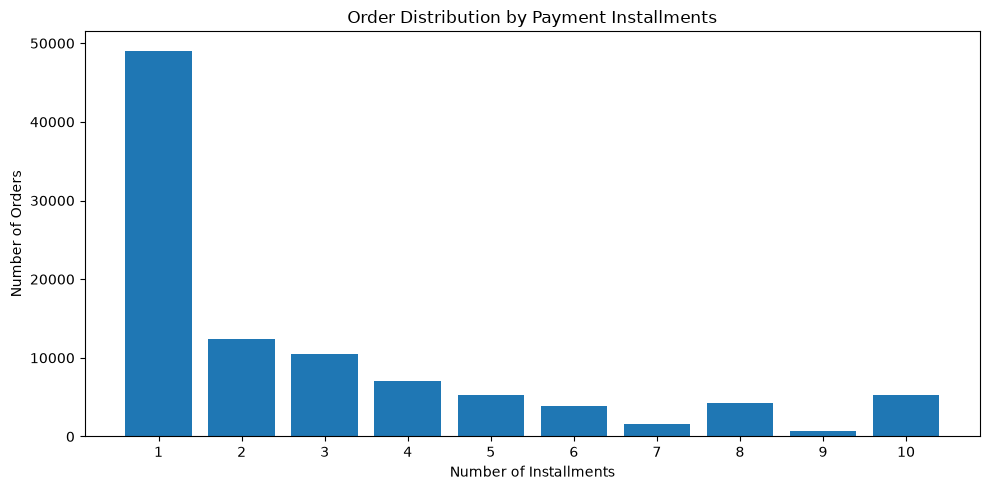

In [200]:
#Installment distribution
installment_chart = installment_analysis[
    (installment_analysis["payment_installments"] >= 1) &
    (installment_analysis["payment_installments"] <= 10)
]

plt.figure(figsize=(10, 5))

plt.bar(
    installment_chart["payment_installments"].astype(str),
    installment_chart["Orders"]
)

plt.xlabel("Number of Installments")
plt.ylabel("Number of Orders")
plt.title("Order Distribution by Payment Installments")

plt.tight_layout()
plt.show()

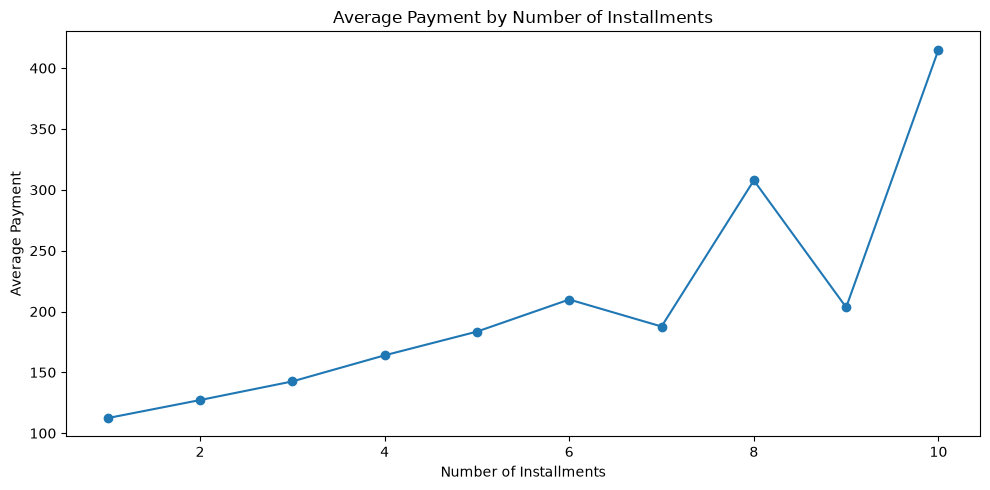

In [201]:
#Payment installments vs average payments
plt.figure(figsize=(10, 5))

plt.plot(
    installment_chart["payment_installments"],
    installment_chart["Average_payment"],
    marker="o"
)

plt.xlabel("Number of Installments")
plt.ylabel("Average Payment")
plt.title("Average Payment by Number of Installments")

plt.tight_layout()
plt.show()

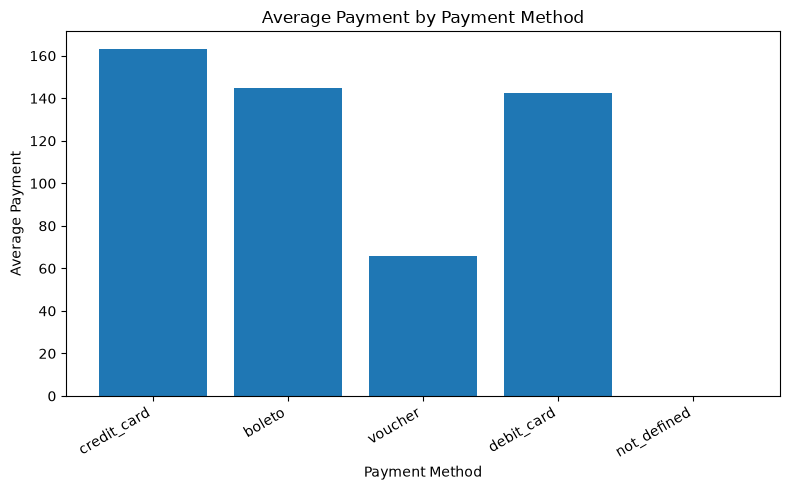

In [202]:
#Payment method vs average payment
plt.figure(figsize=(8, 5))

plt.bar(
    payment_method_analysis["payment_type"],
    payment_method_analysis["Average_Payment"]
)

plt.xlabel("Payment Method")
plt.ylabel("Average Payment")
plt.title("Average Payment by Payment Method")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

In [203]:
#Revenue by customer state
state_revenue = (
    order_sales
    .merge(
        orders[["order_id", "customer_id"]],
        on="order_id",
        how="left"
    )
    .merge(
        customers[["customer_id", "customer_state"]],
        on="customer_id",
        how="left"
    )
    .groupby("customer_state")
    .agg(
        Total_Revenue=("revenue", "sum"),
        Orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
)

state_revenue["Total_Revenue"] = (
    state_revenue["Total_Revenue"].round(2)
)

state_revenue.head(10)

,customer_state,Total_Revenue,Orders
25,SP,5202955.05,41375
18,RJ,1824092.67,12762
10,MG,1585308.03,11544
22,RS,750304.02,5432
17,PR,683083.76,4998
23,SC,520553.34,3612
4,BA,511349.99,3358
6,DF,302603.94,2125
8,GO,294591.95,2007
7,ES,275037.31,2025


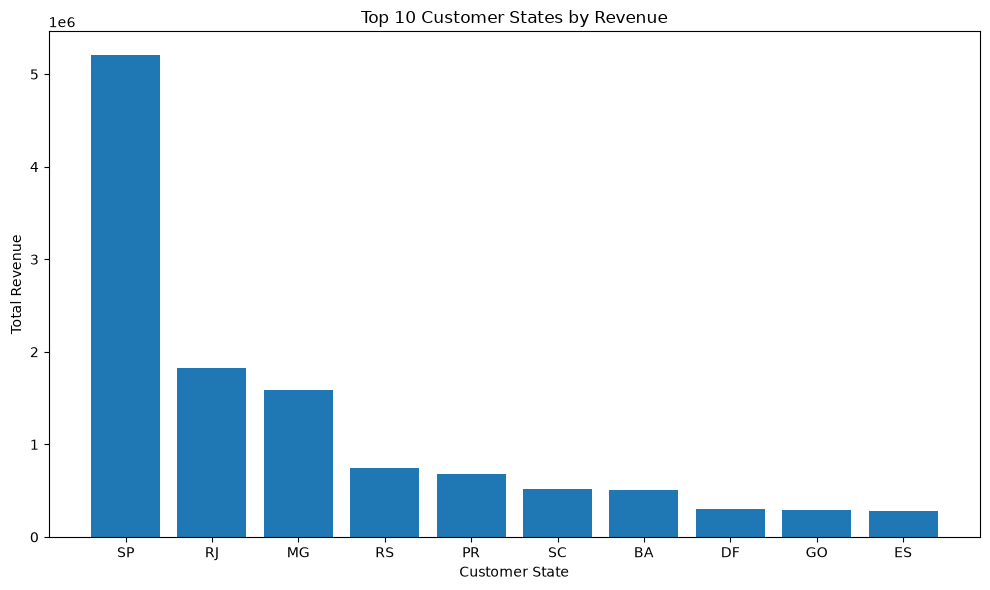

In [204]:
#Revenue by Customer State Chart
top_10_states = state_revenue.head(10)

plt.figure(figsize=(10, 6))

plt.bar(
    top_10_states["customer_state"],
    top_10_states["Total_Revenue"]
)

plt.xlabel("Customer State")
plt.ylabel("Total Revenue")
plt.title("Top 10 Customer States by Revenue")

plt.tight_layout()
plt.show()

In [205]:
#Average Revenue per Order by State
state_revenue["AOV"] = (
    state_revenue["Total_Revenue"]
    / state_revenue["Orders"]
)

state_revenue["AOV"] = (
    state_revenue["AOV"].round(2)
)

state_revenue.sort_values(
    "AOV",
    ascending=False
).head(10)

,customer_state,Total_Revenue,Orders,AOV
14,PB,115268.08,532,216.67
3,AP,13474.30,68,198.15
0,AC,15982.95,81,197.32
1,AL,80314.81,411,195.41
20,RO,46140.64,247,186.80
13,PA,178947.81,970,184.48
26,TO,49621.74,279,177.86
16,PI,86914.08,493,176.30
12,MT,156453.53,903,173.26
19,RN,83034.98,482,172.27


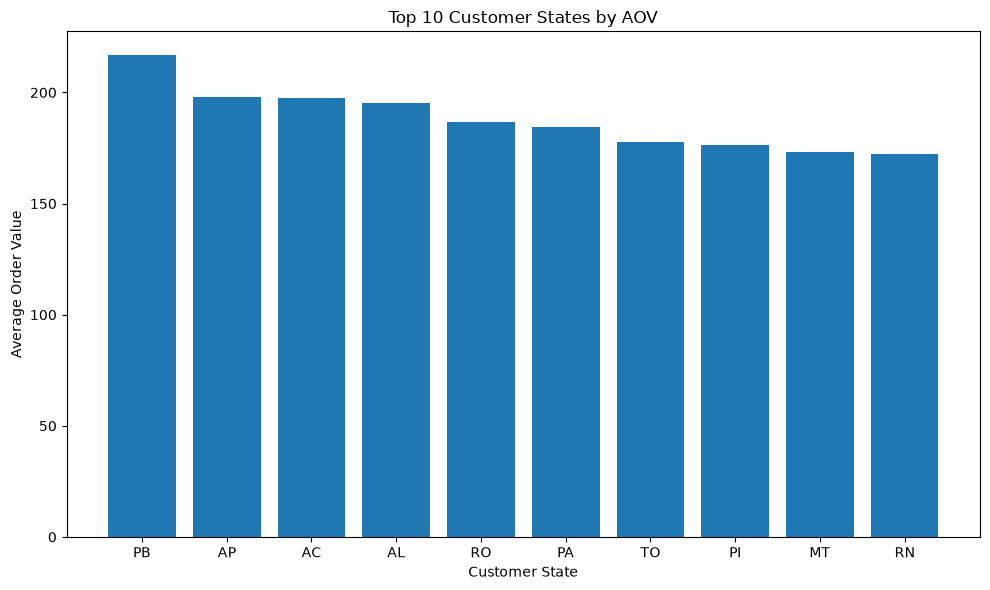

In [206]:
#Top 10 States by AOV
top_10_state_aov = (
    state_revenue
    .sort_values("AOV", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.bar(
    top_10_state_aov["customer_state"],
    top_10_state_aov["AOV"]
)

plt.xlabel("Customer State")
plt.ylabel("Average Order Value")
plt.title("Top 10 Customer States by AOV")

plt.tight_layout()
plt.show()


In [207]:
#state revenue share
state_revenue["Revenue_Share_%"] = (
    state_revenue["Total_Revenue"]
    / state_revenue["Total_Revenue"].sum()
    * 100
)

state_revenue["Revenue_Share_%"] = (
    state_revenue["Revenue_Share_%"].round(2)
)

state_revenue.sort_values(
    "Revenue_Share_%",
    ascending=False
).head(10)

,customer_state,Total_Revenue,Orders,AOV,Revenue_Share_%
25,SP,5202955.05,41375,125.75,38.28
18,RJ,1824092.67,12762,142.93,13.42
10,MG,1585308.03,11544,137.33,11.66
22,RS,750304.02,5432,138.13,5.52
17,PR,683083.76,4998,136.67,5.03
23,SC,520553.34,3612,144.12,3.83
4,BA,511349.99,3358,152.28,3.76
6,DF,302603.94,2125,142.40,2.23
8,GO,294591.95,2007,146.78,2.17
7,ES,275037.31,2025,135.82,2.02


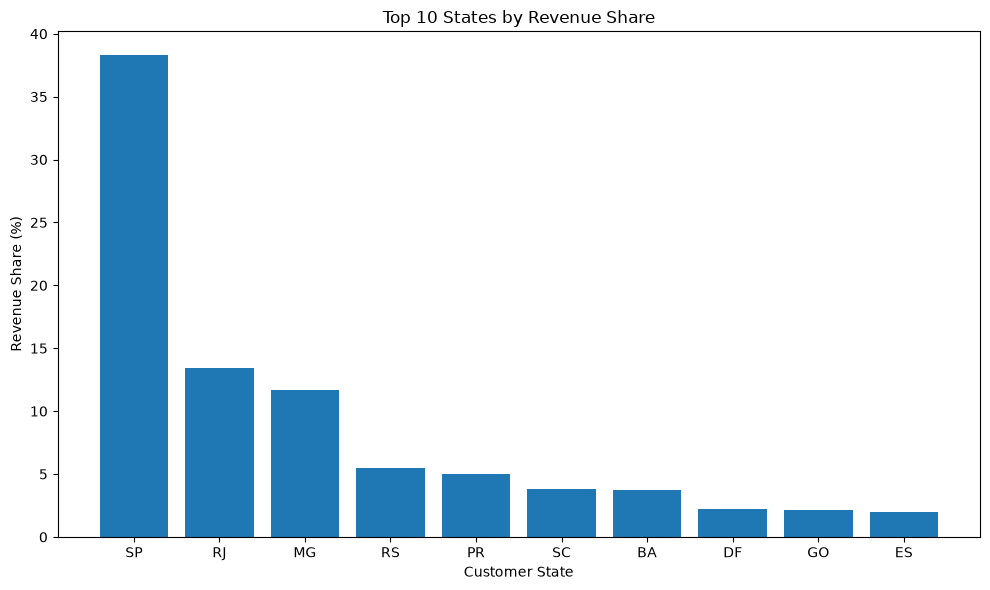

In [208]:
#revenue share by state chart
plt.figure(figsize=(10, 6))

top_10_state_share = (
    state_revenue
    .sort_values("Revenue_Share_%", ascending=False)
    .head(10)
)

plt.bar(
    top_10_state_share["customer_state"],
    top_10_state_share["Revenue_Share_%"]
)

plt.xlabel("Customer State")
plt.ylabel("Revenue Share (%)")
plt.title("Top 10 States by Revenue Share")

plt.tight_layout()
plt.show()

In [209]:
#customer count by state
state_customers = (
    customers
    .groupby("customer_state")
    .agg(
        Customers=("customer_unique_id", "nunique")
    )
    .reset_index()
    .sort_values("Customers", ascending=False)
)

state_customers.head(10)

,customer_state,Customers
25,SP,40302
18,RJ,12384
10,MG,11259
22,RS,5277
17,PR,4882
23,SC,3534
4,BA,3277
6,DF,2075
7,ES,1964
8,GO,1952


In [210]:
#customer share by state
state_customers["Customer_Share_%"] = (
    state_customers["Customers"]
    / state_customers["Customers"].sum()
    * 100
)

state_customers["Customer_Share_%"] = (
    state_customers["Customer_Share_%"].round(2)
)

state_customers.head(10)

,customer_state,Customers,Customer_Share_%
25,SP,40302,41.92
18,RJ,12384,12.88
10,MG,11259,11.71
22,RS,5277,5.49
17,PR,4882,5.08
23,SC,3534,3.68
4,BA,3277,3.41
6,DF,2075,2.16
7,ES,1964,2.04
8,GO,1952,2.03


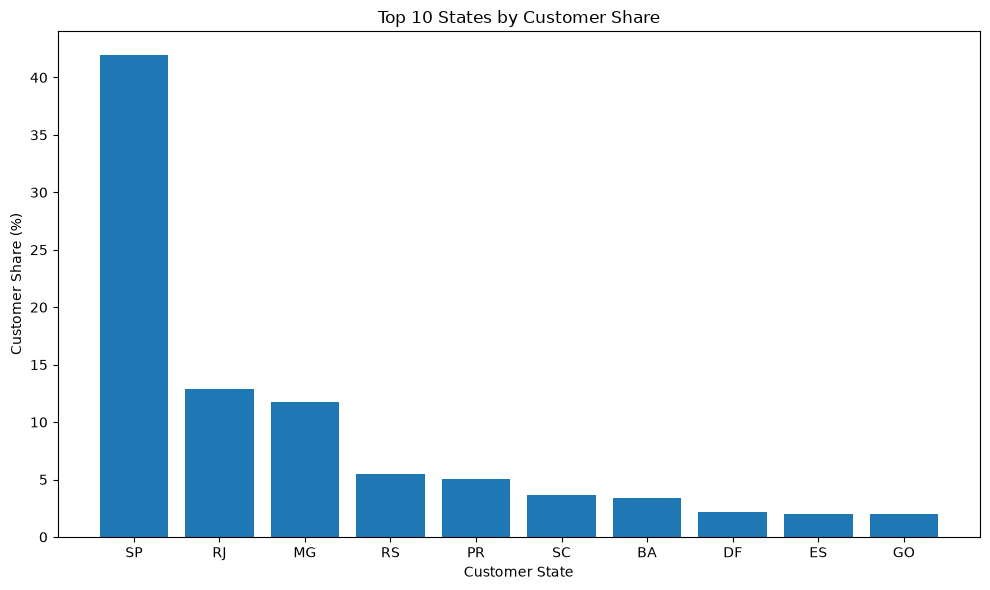

In [211]:
#customer share by state chart
plt.figure(figsize=(10, 6))

top_10_customer_share = (
    state_customers
    .sort_values("Customer_Share_%", ascending=False)
    .head(10)
)

plt.bar(
    top_10_customer_share["customer_state"],
    top_10_customer_share["Customer_Share_%"]
)

plt.xlabel("Customer State")
plt.ylabel("Customer Share (%)")
plt.title("Top 10 States by Customer Share")

plt.tight_layout()
plt.show()

In [212]:
#Revenue per customer by state
state_customer_value = (
    state_revenue
    .merge(
        state_customers[["customer_state", "Customers"]],
        on="customer_state",
        how="left"
    )
)

state_customer_value["Revenue_per_Customer"] = (
    state_customer_value["Total_Revenue"]
    / state_customer_value["Customers"]
)

state_customer_value["Revenue_per_Customer"] = (
    state_customer_value["Revenue_per_Customer"].round(2)
)

state_customer_value = state_customer_value.sort_values(
    "Revenue_per_Customer",
    ascending=False
)

state_customer_value[
    ["customer_state", "Customers", "Total_Revenue", "Revenue_per_Customer"]
].head(10)

,customer_state,Customers,Total_Revenue,Revenue_per_Customer
16,PB,519,115268.08,222.10
24,AC,77,15982.95,207.57
25,AP,67,13474.30,201.11
19,AL,401,80314.81,200.29
22,RO,240,46140.64,192.25
12,PA,949,178947.81,188.56
21,TO,273,49621.74,181.76
17,PI,482,86914.08,180.32
13,MT,876,156453.53,178.60
18,RN,474,83034.98,175.18


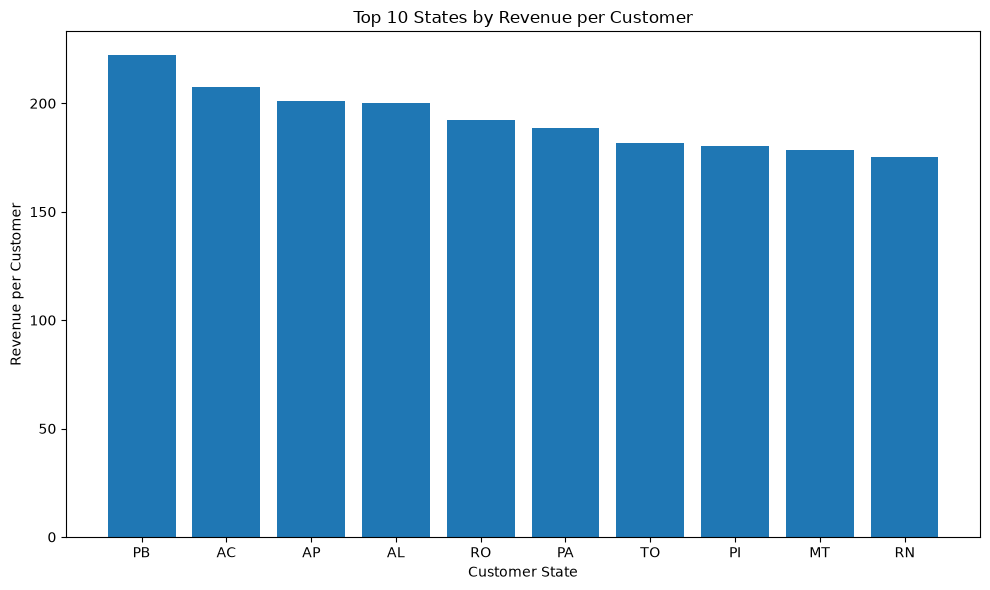

In [213]:
import matplotlib.pyplot as plt

top_10_state_customer_value = state_customer_value.head(10)

plt.figure(figsize=(10, 6))

plt.bar(
    top_10_state_customer_value["customer_state"],
    top_10_state_customer_value["Revenue_per_Customer"]
)

plt.xlabel("Customer State")
plt.ylabel("Revenue per Customer")
plt.title("Top 10 States by Revenue per Customer")
plt.tight_layout()
plt.show()

In [214]:
#Compare revenue share with customer share
state_comparison = state_customer_value.copy()

state_comparison["Customer_Share_%"] = (
    state_comparison["Customers"] / state_comparison["Customers"].sum()
) * 100

state_comparison["Revenue_Share_%"] = (
    state_comparison["Total_Revenue"] / state_comparison["Total_Revenue"].sum()
) * 100

state_comparison["Share_Difference"] = (
    state_comparison["Revenue_Share_%"]
    - state_comparison["Customer_Share_%"]
)

state_comparison[
    [
        "customer_state",
        "Customers",
        "Customer_Share_%",
        "Revenue_Share_%",
        "Share_Difference"
    ]
].sort_values(
    "Share_Difference", ascending=False
).head(10).round(2)

,customer_state,Customers,Customer_Share_%,Revenue_Share_%,Share_Difference
1,RJ,12384,12.88,13.42,0.54
6,BA,3277,3.41,3.76,0.35
12,PA,949,0.99,1.32,0.33
16,PB,519,0.54,0.85,0.31
11,CE,1313,1.37,1.67,0.31
10,PE,1609,1.67,1.93,0.26
13,MT,876,0.91,1.15,0.24
19,AL,401,0.42,0.59,0.17
5,SC,3534,3.68,3.83,0.15
17,PI,482,0.50,0.64,0.14


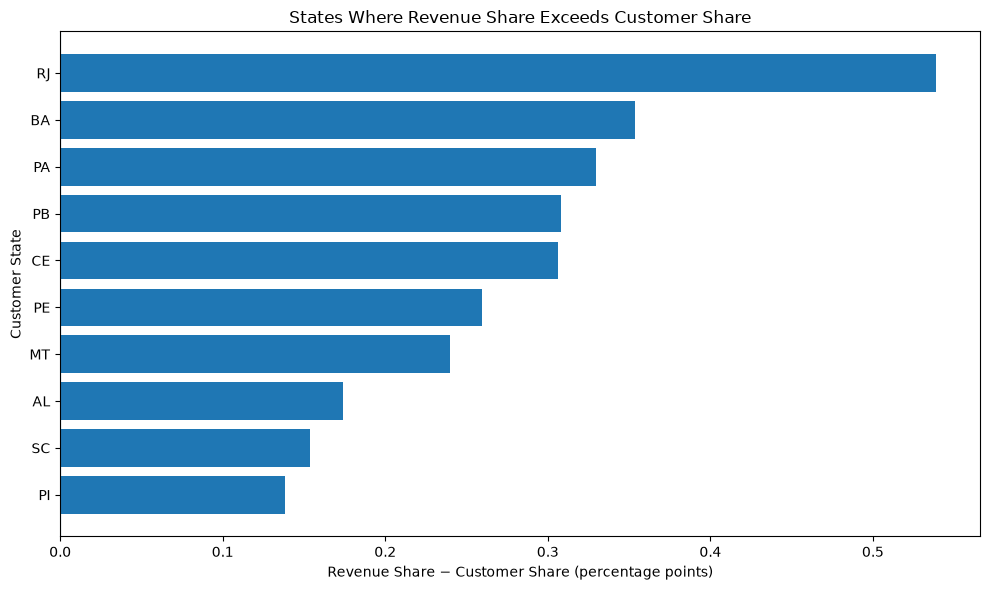

In [215]:
import matplotlib.pyplot as plt

top_10_share_difference = (
    state_comparison
    .sort_values("Share_Difference", ascending=False)
    .head(10)
    .sort_values("Share_Difference")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_share_difference["customer_state"],
    top_10_share_difference["Share_Difference"]
)

plt.xlabel("Revenue Share − Customer Share (percentage points)")
plt.ylabel("Customer State")
plt.title("States Where Revenue Share Exceeds Customer Share")
plt.axvline(x=0)
plt.tight_layout()
plt.show()

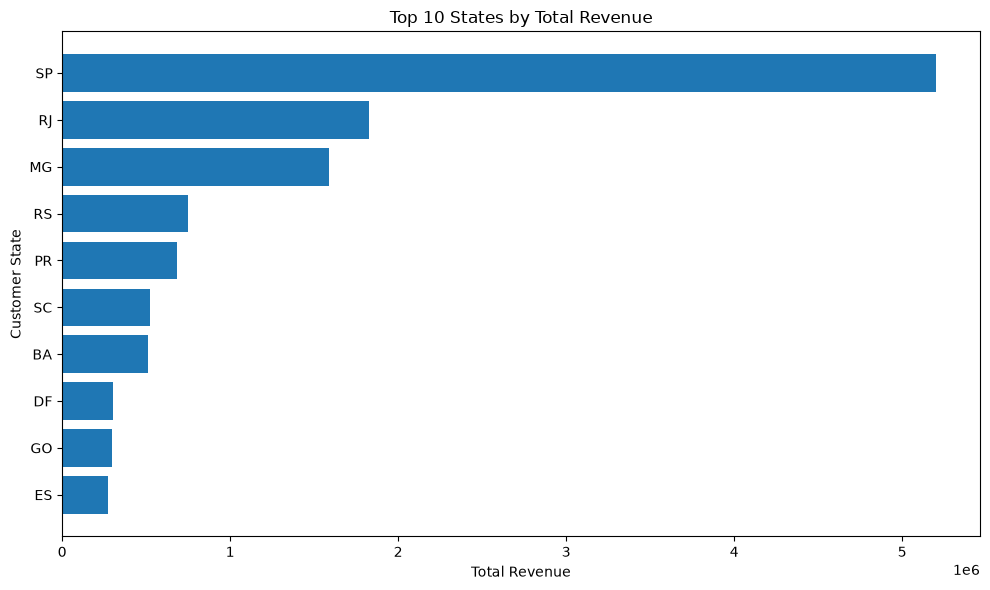

In [216]:
#Identify the top 10 states by total revenue
import matplotlib.pyplot as plt

top_10_states_revenue = state_revenue.head(10).sort_values(
    "Total_Revenue",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_states_revenue["customer_state"],
    top_10_states_revenue["Total_Revenue"]
)

plt.xlabel("Total Revenue")
plt.ylabel("Customer State")
plt.title("Top 10 States by Total Revenue")
plt.tight_layout()
plt.show()

In [217]:
#geographic business insights summary
top_revenue_state = state_revenue.iloc[0]
top_customer_state = state_customers.sort_values(
    "Customers", ascending=False
).iloc[0]
top_value_state = state_customer_value.iloc[0]

print("GEOGRAPHIC BUSINESS INSIGHTS")
print("-" * 40)

print(
    f"Top revenue state: {top_revenue_state['customer_state']} "
    f"({top_revenue_state['Total_Revenue']:,.2f})"
)

print(
    f"Top customer state: {top_customer_state['customer_state']} "
    f"({top_customer_state['Customers']:,} customers)"
)

print(
    f"Highest revenue per customer: {top_value_state['customer_state']} "
    f"({top_value_state['Revenue_per_Customer']:.2f})"
)

GEOGRAPHIC BUSINESS INSIGHTS
----------------------------------------
Top revenue state: SP (5,202,955.05)
Top customer state: SP (40,302 customers)
Highest revenue per customer: PB (222.10)


In [218]:
#final project insights summary
print("E-COMMERCE BUSINESS KPI SUMMARY")
print("=" * 45)

print(f"Total customers: {customers['customer_unique_id'].nunique():,}")
print(f"Total orders: {orders['order_id'].nunique():,}")
print(f"Delivered orders: {(orders['order_status'] == 'delivered').sum():,}")
print(f"Total product revenue: {order_sales.loc[order_sales['order_status'] == 'delivered', 'revenue'].sum():,.2f}")
print(f"Average order value: {order_sales.loc[order_sales['order_status'] == 'delivered'].groupby('order_id')['revenue'].sum().mean():.2f}")
print(f"Average review score: {reviews['review_score'].mean():.2f}/5")

E-COMMERCE BUSINESS KPI SUMMARY
Total customers: 96,096
Total orders: 99,441
Delivered orders: 96,478
Total product revenue: 13,221,498.11
Average order value: 137.04
Average review score: 4.09/5


In [219]:
#reusable KPI summary table
kpi_summary = pd.DataFrame({
    "KPI": [
        "Unique Customers",
        "Total Orders",
        "Delivered Orders",
        "Delivered Product Revenue",
        "Average Order Value",
        "Average Review Score"
    ],
    "Value": [
        customers["customer_unique_id"].nunique(),
        orders["order_id"].nunique(),
        (orders["order_status"] == "delivered").sum(),
        round(
            order_sales.loc[
                order_sales["order_status"] == "delivered",
                "revenue"
            ].sum(), 2
        ),
        round(
            order_sales.loc[
                order_sales["order_status"] == "delivered"
            ].groupby("order_id")["revenue"].sum().mean(), 2
        ),
        round(reviews["review_score"].mean(), 2)
    ]
})

kpi_summary

,KPI,Value
0,Unique Customers,96096.00
1,Total Orders,99441.00
2,Delivered Orders,96478.00
3,Delivered Product Revenue,13221498.11
4,Average Order Value,137.04
5,Average Review Score,4.09


In [220]:
#Exporting KPI summary to CSV
kpi_summary.to_csv(
    "../kpi_summary.csv",
    index=False
)

print("KPI summary exported successfully!")

KPI summary exported successfully!


In [221]:
#final business insights report
business_insights = [
    "1. Geographic Performance: SP (Sao Paulo) generated the highest revenue "
    "at 5,202,955.05 and had 40,302 customers.",

    "2. Customer Value: PB had the highest revenue per customer at 222.10.",

    "3. Customer Reviews: The average review score was 4.09 out of 5.",

    "4. Order Performance: 96,478 orders were delivered out of 99,441 total orders.",

    "5. Revenue: Delivered product revenue was 13,221,498.11, "
    "with an average order value of 137.04.",

    "6. Business Recommendation: Maintain the strong SP market while "
    "investigating high revenue per customer in PB and other promising states."
]

with open("../business_insights.txt", "w", encoding="utf-8") as file:
    file.write("E-COMMERCE REVENUE & CUSTOMER ANALYTICS\n")
    file.write("=" * 45 + "\n\n")

    for insight in business_insights:
        file.write(insight + "\n\n")

print("Business insights report exported successfully!")

Business insights report exported successfully!


In [222]:
state_comparison.to_csv(
    "../state_revenue_customer_analysis.csv",
    index=False
)

print("Geographic analysis exported successfully!")

Geographic analysis exported successfully!
